# **4. Forecasting daily occupancy**

Chapter 3 gave us a synthetic daily history. Chapter 4 asks the practical question:
how well can we forecast the next four weeks of occupancy for a destination, and does
a smarter model beat simple rules? We build the yardstick first and the models after.

## **4.1 The forecasting task, four baselines and a ceiling**

### **4.1.1 The task**
- **Forecast:** daily occupancy for each of the five destinations, **28 days ahead**.
- **Rolling origin:** every Sunday from 2 Feb 2025 (so 13 months of history exist for
  the year-ago methods) until the last date that still has 28 days of actuals.
  At each origin a method may use only data up to and including that Sunday.
- **No leakage:** each method receives only the data up to its origin.

### **4.1.2 Four baselines (simple rules, no learning)**
1. **Last week, same weekday.** Copy the most recent matching weekday.
2. **Mean of the last 4 same weekdays.** The same idea with less noise.
3. **Last year, same weekday** (364 days earlier, so weekdays line up).
4. **Last year x recent growth.** Method 3 times the ratio of the last 28 days to the
   same 28 days a year earlier. This is the method that won in Chapter 1.

### **4.1.3 The ceiling**
An **oracle** that knows the exact generating rules but not the random noise. It is only
possible because the data are synthetic, and its error is the floor for any model: the
part of the error nobody can remove. Models will be judged on how much of the gap
between the best baseline and the oracle they close.

### **4.1.4 Metrics**
Mean absolute error in **occupancy points** (1 point = 1% of rooms), the mean error
(bias), and error by horizon band: days 1-7, 8-14 and 15-28.

### **4.1.5 Predictions (written before the run)**
1. The oracle's error is **4 to 6 points** (12% daily noise on occupancy near 0.5).
2. Every baseline lands **between 6.5 and 14 points**.
3. The **mean of the last 4 same weekdays beats last week** overall (averaging cuts noise).
4. **Last year x recent growth beats plain last year**, which should be biased low by
   about 2 to 4 points because the market grew.

### **4.1.6 Decision rule for the models in 4.3**
A model earns its place only if it (a) beats the best baseline by at least 1 point of
overall error, (b) closes at least one third of the gap between the best baseline and
the oracle, and (c) is not worse than the best baseline by more than 0.5 point in
any destination.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd

sys.path.insert(0, str(Path("../src").resolve()))
import locat.forecasting.synthetic as synth

out_dir = Path("../data/processed")
DESTINATIONS = ["Maasai Mara", "Naivasha", "Diani", "Lamu", "Amboseli"]
HORIZON = 28
HISTORY_END = pd.Timestamp("2026-11-05")

# ---- data ----
syn = pd.read_csv(out_dir / "synthetic_occupancy.csv", parse_dates=["date"])
occ = syn.pivot(index="date", columns="destination", values="occupancy")[DESTINATIONS]
print("history:", occ.index.min().date(), "to", occ.index.max().date(), "| days:", len(occ))

# ---- the oracle: the generator without noise, rebuilt from the saved assumptions ----
assump = json.loads((out_dir / "synthetic_assumptions.json").read_text())
params = pd.DataFrame(assump["params"])
month_adjust = pd.DataFrame.from_dict(assump["month_adjust"], orient="index")
settings = assump["globals"]
cal = pd.read_csv(out_dir / "calendar_daily.csv", parse_dates=["date"])
seasonal = pd.read_csv(out_dir / "seasonal_index.csv")
idx_map = dict(zip(seasonal["month_number"], seasonal["seasonal_index"]))

oracle_hist = synth.generate_history(
    cal, params, month_adjust, dict(settings, noise_sd=0.0), idx_map, HISTORY_END
)
oracle = oracle_hist.pivot(index="date", columns="destination", values="occupancy")[DESTINATIONS]

# ---- rolling origins ----
FIRST_ORIGIN = pd.Timestamp("2025-02-02")  # a Sunday
last_origin = occ.index.max() - pd.Timedelta(days=HORIZON)
origins = pd.date_range(FIRST_ORIGIN, last_origin, freq="7D")
print(f"origins: {len(origins)} weekly | first {origins[0].date()} | last {origins[-1].date()}")


# ---- forecasting methods: each sees only `train` (data up to the origin) ----
def _dates(origin, horizon):
    return pd.date_range(origin + pd.Timedelta(days=1), periods=horizon)


def _lag7(horizon):
    """Smallest multiple of 7 days that reaches back to the last observed week."""
    return 7 * np.ceil(np.arange(1, horizon + 1) / 7).astype(int)


def fc_last_week(train, origin, horizon, dest):
    dates = _dates(origin, horizon)
    vals = [train.loc[d - pd.Timedelta(days=int(l))] for d, l in zip(dates, _lag7(horizon))]
    return pd.Series(vals, index=dates)


def fc_last4_weeks(train, origin, horizon, dest):
    dates = _dates(origin, horizon)
    vals = [
        np.mean([train.loc[d - pd.Timedelta(days=int(l) + 7 * j)] for j in range(4)])
        for d, l in zip(dates, _lag7(horizon))
    ]
    return pd.Series(vals, index=dates)


def fc_last_year(train, origin, horizon, dest):
    dates = _dates(origin, horizon)
    return pd.Series([train.loc[d - pd.Timedelta(days=364)] for d in dates], index=dates)


def fc_last_year_growth(train, origin, horizon, dest):
    base = fc_last_year(train, origin, horizon, dest)
    recent = train.loc[origin - pd.Timedelta(days=27): origin].sum()
    year_ago = train.loc[origin - pd.Timedelta(days=27 + 364): origin - pd.Timedelta(days=364)].sum()
    return base * (recent / year_ago)


def fc_oracle(train, origin, horizon, dest):
    return oracle.loc[_dates(origin, horizon), dest]


def evaluate(fn, name):
    parts = []
    for dest in DESTINATIONS:
        s = occ[dest]
        for o in origins:
            f = fn(s.loc[:o], o, HORIZON, dest)
            parts.append(pd.DataFrame({
                "method": name, "destination": dest, "origin": o,
                "h": np.arange(1, HORIZON + 1), "date": f.index,
                "forecast": f.values, "actual": s.loc[f.index].values,
            }))
    return pd.concat(parts, ignore_index=True)


methods = {
    "last_week_same_weekday": fc_last_week,
    "mean_last_4_same_weekdays": fc_last4_weeks,
    "last_year_same_weekday": fc_last_year,
    "last_year_x_recent_growth": fc_last_year_growth,
    "oracle_knows_the_rules": fc_oracle,
}
results = pd.concat([evaluate(fn, name) for name, fn in methods.items()], ignore_index=True)
results["error_pts"] = 100 * (results["forecast"] - results["actual"])
results["abs_error_pts"] = results["error_pts"].abs()
results["bucket"] = pd.cut(results["h"], [0, 7, 14, 28], labels=["days 1-7", "days 8-14", "days 15-28"])

# ---- results ----
order = list(methods)
mae = results.pivot_table(index="method", columns="destination", values="abs_error_pts", aggfunc="mean")[DESTINATIONS]
mae["ALL"] = results.groupby("method")["abs_error_pts"].mean()
print("\nMAE in occupancy points (1 point = 1% of rooms):")
print(mae.loc[order].round(1).to_string())

print("\nMean error (bias), points; negative = forecast too low:")
print(results.groupby("method")["error_pts"].mean().loc[order].round(2).to_string())

by_h = results.pivot_table(index="method", columns="bucket", values="abs_error_pts",
                           aggfunc="mean", observed=True).loc[order]
print("\nMAE by forecast horizon:")
print(by_h.round(1).to_string())

baselines = order[:-1]
best = mae.loc[baselines, "ALL"].idxmin()
print(f"\nBest baseline: {best} ({mae.loc[best, 'ALL']:.1f} pts) | "
      f"ceiling: {mae.loc['oracle_knows_the_rules', 'ALL']:.1f} pts")
print(f"rows evaluated per method: {len(results) // len(methods):,}")

results.drop(columns=["bucket"]).to_csv(out_dir / "backtest_baselines.csv", index=False)

history: 2024-01-01 to 2026-11-05 | days: 1040
origins: 88 weekly | first 2025-02-02 | last 2026-10-04

MAE in occupancy points (1 point = 1% of rooms):
destination                Maasai Mara  Naivasha  Diani  Lamu  Amboseli  ALL
method                                                                      
last_week_same_weekday             9.1       9.1   11.0   9.0       8.7  9.4
mean_last_4_same_weekdays          8.6       8.1   11.3   9.1       8.6  9.1
last_year_same_weekday             7.8       7.1    7.9   6.6       7.4  7.4
last_year_x_recent_growth          8.0       7.3    8.1   6.7       7.3  7.5
oracle_knows_the_rules             5.6       3.9    5.0   4.4       4.9  4.8

Mean error (bias), points; negative = forecast too low:
method
last_week_same_weekday      -0.14
mean_last_4_same_weekdays   -0.22
last_year_same_weekday      -2.61
last_year_x_recent_growth    0.10
oracle_knows_the_rules       0.12

MAE by forecast horizon:
bucket                     days 1-7  days 8-14  

## **4.2 Review of results: baselines and ceiling (step 4.1)**

### **4.2.1 Verdict**
The yardstick works. The ceiling is 4.8 points, the best baseline is 7.4 points, and
the gap between them is 2.6 points: that is the room a model has to improve. Three of
the four predictions written in 4.1.5 held. The fourth held in its cause (bias) but
failed in its effect (error), and the reason is instructive.

### **4.2.2 Prediction scorecard**

| Prediction (4.1.5) | Result | Verdict |
|---|---|---|
| Oracle error is 4 to 6 points | 4.8 overall (3.9 to 5.6 by destination) | Held |
| Every baseline is between 6.5 and 14 points | 6.6 to 11.3 by destination; 7.4 to 9.4 overall | Held (Lamu, last year, is 6.6, just inside) |
| Mean of last 4 weekdays beats last week | 9.1 against 9.4 overall | Held, but only by 0.3, and it loses in Diani (11.3 against 11.0) and Lamu (9.1 against 9.0) |
| Last year x growth beats last year; last year is biased low by 2 to 4 points | Bias -2.61, as predicted; but error 7.5 against 7.4 | Half right: bias held, error improvement failed |

### **4.2.3 What the numbers show**

#### **4.2.3.1 The ceiling**
Oracle error is 4.8 points overall and flat across horizons (4.8, 4.8, 4.8), as it
should be, since it knows the rules and nothing about the noise. It matches the
back-of-envelope figure (12% daily noise x occupancy near 0.5 x 0.8 = about 4.8).
Naivasha has the lowest floor (3.9) because its occupancy is lowest, so the same
percentage noise is fewer points; Maasai Mara has the highest (5.6).

#### **4.2.3.2 Baselines**

| Method | MAE overall | Days 1-7 | Days 8-14 | Days 15-28 |
|---|---|---|---|---|
| Last week, same weekday | 9.4 | 8.1 | 8.9 | 10.3 |
| Mean of last 4 same weekdays | 9.1 | 7.7 | 8.7 | 10.0 |
| Last year, same weekday | 7.4 | 7.4 | 7.3 | 7.4 |
| Last year x recent growth | 7.5 | 7.4 | 7.5 | 7.5 |

The two week-based rules get worse with horizon (8.1 to 10.3), because they freeze the
most recent week and miss what changes later: school breaks, long weekends, season.
The two year-ago rules are flat at about 7.4 and beat the week-based ones even in days
1-7. A likely reason is that the school calendar and the seasons fall on nearly the
same dates every year, so a year-old value carries them. That is a hypothesis. It also
means a model that uses the calendar directly has a lot to gain over last-week rules.
The week-based rules do worst in Diani (11.0 and 11.3), the destination with the
steepest year-end swing.

#### **4.2.3.3 The bias in the year-ago rule**
Last year's value is 2.61 points too low on average. That is almost exactly 5% market
growth applied to occupancy near 0.5 (0.05 x 0.5 = 2.5 points), a clean check that the
growth assumption works as designed. Scaling by recent growth removes the bias (+0.10)
but not the error (7.5 against 7.4). A rough estimate explains why: removing a 2.6-point
bias is worth about 0.3 points of error, but the growth ratio is itself noisy (it comes
from two noisy 28-day sums), and multiplying every forecast by it costs about the same.
These are approximate figures, not measured ones. It also repeats the Chapter 1 lesson
that simple growth adjustments help only when the level estimate is reliable.

#### **4.2.3.4 What a model must achieve**
The decision rule in 4.1.6 requires beating the best baseline by at least 1 point, so a
model must reach 6.4 points or better overall. That is 38% of the 2.6-point gap, so the
rule on the size of the improvement is stricter than the one-third-of-the-gap rule.

### **4.2.4 Limits**
- All results are on synthetic data; they show how methods rank when the world follows
  our rules. They do not prove how they rank on real bookings.
- The 88 origins overlap (each forecast window shares data with its neighbours), so
  the origins are not independent samples, and small differences, such as the 0.3 between
  the two week-based rules, should not be over-read.

### **4.2.5 Decision**
Move on to models. The best baseline to beat is "last year, same weekday" at 7.4.

## **4.3 Next step: a calendar-feature model, tested by removing pieces**

### **4.3.1 Why**
The baselines copy past values. A model can instead learn how each calendar driver
(weekends, school breaks, long weekends, season, growth) moves occupancy and apply
that to future dates. We start with the simplest model that could work, a ridge
regression on the logarithm of occupancy, because it is fast, stable with about two
years of data, and its results can be read.

### **4.3.2 Model**
- One model per destination, refitted every week on data up to the origin, so it
  sees exactly what a host would have seen.
- Target: log occupancy. A multiplicative world becomes additive on the log scale.
  The forecast is the exponential of the prediction, which suits an absolute-error
  measure.
- Features, all known in advance for any future date: Friday/Saturday night, school
  break, long weekend, Easter period, payday window, the log of the smoothed
  international index, three pairs of annual sine and cosine terms (a flexible
  seasonal curve), and a linear time trend (growth).
- Ridge strength is fixed at 1.0 (on standardised features) and not tuned.

### **4.3.3 Three versions (an ablation)**
1. **Full:** all features.
2. **No international index:** does the real KNBS information help?
3. **No calendar flags:** season and trend only. What do the calendar flags add?

### **4.3.4 Caveat about information leakage**
The international index was built from 2024 and 2025 arrivals, so using it for a 2025
origin lets the model see slightly ahead. It mostly encodes the annual shape, which the
sine and cosine terms can also learn, so the effect should be small. Version 2 shows how
much the index matters. For the live forecast from November 2026 there is no leakage.

### **4.3.5 Predictions (written before the run)**
1. The full model's error is **between 5.3 and 6.3 points** and passes the rule in
   4.2.3.4 (6.4 or better).
2. Removing the international index changes the error by **less than 0.3 points** in
   every destination, because the sine and cosine terms learn the same annual shape.
3. Removing the calendar flags raises the error by **at least 2 points overall**, with
   the largest rise in Naivasha (**3 points or more**), the most domestic destination
   with the strongest weekend and school effects.
4. The full model's error is **flat across horizons** (within 0.3 points), unlike the
   week-based baselines.

### **4.3.6 Decision rule**
The full model must pass the three conditions in 4.1.6. If it does not, we look at
where it fails before trying a more complex model.

In [2]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# ---- calendar features, known in advance for any future date ----
feat = cal.set_index("date")
X_all = pd.DataFrame(index=feat.index)
FLAG_COLS = ["fri_sat_night", "school_out", "is_long_weekend", "easter_period", "payday_window"]
for c in FLAG_COLS:
    X_all[c] = feat[c].astype(float)
X_all["log_intl"] = np.log(synth.smooth_intl_index(pd.Series(feat.index), idx_map))
doy = feat.index.dayofyear.to_numpy()
for k in (1, 2, 3):
    X_all[f"sin{k}"] = np.sin(2 * np.pi * k * doy / 365.25)
    X_all[f"cos{k}"] = np.cos(2 * np.pi * k * doy / 365.25)
X_all["trend"] = ((X_all.index - pd.Timestamp("2024-01-01")).days / 365.25).to_numpy()
print("features:", list(X_all.columns))


def make_ridge_forecaster(alpha, columns):
    def fc(train, origin, horizon, dest):
        dates = _dates(origin, horizon)
        model = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
        model.fit(X_all.loc[train.index, columns], np.log(train.values))
        pred = np.exp(model.predict(X_all.loc[dates, columns]))
        return pd.Series(np.clip(pred, 0.01, 0.98), index=dates)
    return fc


all_cols = list(X_all.columns)
variants = {
    "ridge_full": all_cols,
    "ridge_no_intl_index": [c for c in all_cols if c != "log_intl"],
    "ridge_no_calendar_flags": [c for c in all_cols if c not in FLAG_COLS],
}

new = pd.concat(
    [evaluate(make_ridge_forecaster(1.0, cols), name) for name, cols in variants.items()],
    ignore_index=True,
)
new["error_pts"] = 100 * (new["forecast"] - new["actual"])
new["abs_error_pts"] = new["error_pts"].abs()
new["bucket"] = pd.cut(new["h"], [0, 7, 14, 28], labels=["days 1-7", "days 8-14", "days 15-28"])

res = pd.concat([results, new], ignore_index=True)
order2 = baselines + list(variants) + ["oracle_knows_the_rules"]

mae2 = res.pivot_table(index="method", columns="destination", values="abs_error_pts", aggfunc="mean")[DESTINATIONS]
mae2["ALL"] = res.groupby("method")["abs_error_pts"].mean()
print("\nMAE in occupancy points:")
print(mae2.loc[order2].round(1).to_string())

print("\nMean error (bias), points:")
print(res.groupby("method")["error_pts"].mean().loc[order2].round(2).to_string())

by_h2 = res.pivot_table(index="method", columns="bucket", values="abs_error_pts",
                        aggfunc="mean", observed=True).loc[order2]
print("\nMAE by forecast horizon:")
print(by_h2.round(1).to_string())

best_name = mae2.loc[baselines, "ALL"].idxmin()
best_mae = mae2.loc[best_name, "ALL"]
oracle_mae = mae2.loc["oracle_knows_the_rules", "ALL"]
print(f"\nBest baseline: {best_name} ({best_mae:.1f}) | ceiling: {oracle_mae:.1f}")
for name in variants:
    m = mae2.loc[name, "ALL"]
    closed = (best_mae - m) / (best_mae - oracle_mae)
    worst = (mae2.loc[name, DESTINATIONS] - mae2.loc[best_name, DESTINATIONS]).max()
    print(f"{name:26s} MAE {m:.1f} | beats best baseline by {best_mae - m:+.1f} "
          f"| gap closed {closed:.0%} | worst destination vs best baseline {worst:+.1f}")

res.drop(columns=["bucket"]).to_csv(out_dir / "backtest_models.csv", index=False)

features: ['fri_sat_night', 'school_out', 'is_long_weekend', 'easter_period', 'payday_window', 'log_intl', 'sin1', 'cos1', 'sin2', 'cos2', 'sin3', 'cos3', 'trend']

MAE in occupancy points:
destination                Maasai Mara  Naivasha  Diani  Lamu  Amboseli  ALL
method                                                                      
last_week_same_weekday             9.1       9.1   11.0   9.0       8.7  9.4
mean_last_4_same_weekdays          8.6       8.1   11.3   9.1       8.6  9.1
last_year_same_weekday             7.8       7.1    7.9   6.6       7.4  7.4
last_year_x_recent_growth          8.0       7.3    8.1   6.7       7.3  7.5
ridge_full                         5.9       4.0    5.8   5.1       5.5  5.2
ridge_no_intl_index                6.0       3.9    5.7   5.2       5.6  5.3
ridge_no_calendar_flags            6.0       9.4    7.3   5.9       5.6  6.8
oracle_knows_the_rules             5.6       3.9    5.0   4.4       4.9  4.8

Mean error (bias), points:
method
last_

## **4.4 Review of results: the calendar-feature model (step 4.3)**

### **4.4.1 Verdict**
The full ridge model passes all three decision rules from 4.1.6 with room to spare. It
reaches 5.2 points of error against 7.4 for the best baseline, and the ceiling is 4.8, so
it closes 82% of the gap. It also beats the best baseline in every destination. Two of
the four predictions held outright, one held on its main point, and one missed by 0.4
points in the optimistic direction, so the ablation told us more than the headline did.

### **4.4.2 Prediction scorecard**

| Prediction (4.3.5) | Result | Verdict |
|---|---|---|
| Full model error is 5.3 to 6.3 and passes the 6.4 rule | 5.2, and it passes | Passes the rule; the range was 0.1 too pessimistic |
| Removing the international index changes error by less than 0.3 in every destination | Changes of 0.1 or less everywhere (5.2 against 5.3 overall) | Held |
| Removing the calendar flags raises error by at least 2 points overall, 3 or more in Naivasha | +1.6 overall; Naivasha +5.4 | Naivasha held strongly; the overall figure missed |
| Full model error is flat across horizons | 5.2, 5.2, 5.3 | Held |

### **4.4.3 What the numbers show**

#### **4.4.3.1 Decision rule check (full model)**
- **Beats the best baseline by at least 1 point:** yes, by 2.1 points (5.2 against 7.4).
- **Closes at least a third of the gap to the ceiling:** yes, 82%.
- **Not worse than the best baseline by more than 0.5 in any destination:** yes; it
  is better in every destination, and its weakest margin is 1.5 points.

#### **4.4.3.2 Where the remaining 0.4 points to the ceiling live**

| Destination | Ridge full | Oracle | Remaining gap |
|---|---|---|---|
| Maasai Mara | 5.9 | 5.6 | 0.3 |
| Naivasha | 4.0 | 3.9 | 0.1 |
| Diani | 5.8 | 5.0 | 0.8 |
| Lamu | 5.1 | 4.4 | 0.7 |
| Amboseli | 5.5 | 4.9 | 0.6 |

The gap is largest at the two coast destinations. A candidate explanation: in our
generator their own monthly seasons change in steps at month boundaries (for example
Diani goes from 1.20 in December to 1.15 in January, and drops to 0.75 in May), and
three sine and cosine pairs cannot reproduce steps. That is a hypothesis. It is also a
generator artifact, since real seasons change more smoothly. Chasing it would mean
fitting our own simplification, so we do not.

#### **4.4.3.3 The ablation: what each piece contributes**

| Destination | Full | No international index | No calendar flags | Flags effect | Domestic share |
|---|---|---|---|---|---|
| Maasai Mara | 5.9 | 6.0 | 6.0 | +0.1 | 40% |
| Naivasha | 4.0 | 3.9 | 9.4 | +5.4 | 90% |
| Diani | 5.8 | 5.7 | 7.3 | +1.5 | 55% |
| Lamu | 5.1 | 5.2 | 5.9 | +0.8 | 55% |
| Amboseli | 5.5 | 5.6 | 5.6 | +0.1 | 35% |

- **The calendar flags matter in proportion to the domestic share of guests,** which is
  what the generator was built to do. In a destination that mostly hosts Kenyans
  (Naivasha) the flags cut the error from 9.4 to 4.0; in the safari destinations they
  hardly matter, and season carries the forecast. I mis-estimated the overall figure
  because I treated every destination like Naivasha.
- **The international index adds nothing beyond the seasonal curve the model learns from
  the destination's own history** (changes of 0.1 or less). That is a statement about this
  data. The index will still matter for a **new host with no booking history**, for whom
  it is the only seasonal information, so we keep it in the model for them.

#### **4.4.3.4 Bias**
The full model is 0.41 points low on average. That is close to what taking the
exponential of a log-scale prediction produces (it gives the median, which lies below
the mean by about 0.7% of occupancy, roughly 0.4 points at occupancy near 0.5).
This is the right choice for absolute error. If the price advisor later needs the
expected value, we add a small correction.

### **4.4.4 Limits**
- The generator is close to the model's own form (multiplicative effects, a smooth
  seasonal curve), so part of this success is by construction. The real test is real
  bookings after launch.
- The international-index leakage caveat from 4.3.4 stands, and the ablation shows it
  did not matter here.
- The 88 origins overlap, so the figures are not 88 independent trials.

### **4.4.5 Decision**
Adopt the ridge model as the forecaster. We drop gradient boosting for now: the model
is within 0.4 points of the best possible score, so there is little left for a more
complex model to gain on this data, and it could not be told apart from noise. We revisit
it when real bookings exist. Next: check that the model's *explanations* match the
answer key (4.5), then add prediction intervals, then move the model into the project.

## **4.5 Next step: do the model's effects match the answer key?**

### **4.5.1 Why**
The price advisor will explain itself, for example "school holidays lift demand at your
place by about 30%". Those sentences are only honest if the model recovered the true
effects. Predicting well is not the same as explaining well: effects can trade off
against each other, such as school breaks against the annual season, and still forecast
well.

### **4.5.2 Method**
1. Fit the full model for each destination on all history (to 5 Nov 2026).
2. Read each flag's effect as a multiplier: the exponential of its coefficient in the
   original units (the scaling is undone).
3. Compare with the answer key from 3.10 (noise-free, fixed-effects). An effect counts as
   **recovered** if it lies within 2 seed-to-seed standard deviations of the key.
4. Easter and payday have no key, so we compare with the approximate mixing-rule target:
   international share + (1 - international share) x the assumed boost.
5. Check the implied yearly growth against the assumed 5%.

### **4.5.3 Predictions (written before the run)**
1. **Weekend:** all 5 destinations recovered (the effect is strong and measured often).
2. **School break:** at most 3 of 5 recovered. School breaks fall on nearly the same dates
   each year, so they are partly confounded with the annual seasonal curve.
3. **Long weekend:** at least 3 of 5 recovered (the tolerance is wide, 0.07 to 0.08).
4. **Payday:** within 0.03 of the approximate target in every destination. **Easter:**
   within 0.08 in at least 3 of 5 (only about 15 training days, and it overlaps long
   weekends and the April school break).
5. **Implied growth:** between 3% and 8% in every destination.

### **4.5.4 Decision rule**
- If at least 12 of the 15 key cells are recovered, the advisor may quote the model's
  effects directly.
- Otherwise it quotes only the effects that were recovered, and for the others we say
  "around X%" using the answer key's range, or leave them out of the explanation.

In [3]:
# ---- fit the full model on all history; read each flag's effect as a multiplier ----
ref = pd.read_csv(out_dir / "synthetic_uplift_reference.csv", index_col=[0, 1])
key = ref.loc["noise_free_fe"].loc[DESTINATIONS]
key_sd = ref.loc["sd_20_seeds_fe"].loc[DESTINATIONS]

rows, growth_implied = {}, {}
for dest in DESTINATIONS:
    model = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
    model.fit(X_all.loc[occ.index, all_cols], np.log(occ[dest].values))
    coef = pd.Series(
        model.named_steps["ridge"].coef_ / model.named_steps["standardscaler"].scale_,
        index=all_cols,
    )
    rows[dest] = np.exp(coef[FLAG_COLS])
    growth_implied[dest] = np.exp(coef["trend"]) - 1
effects = pd.DataFrame(rows).T.loc[DESTINATIONS]

model_vs_key = pd.DataFrame({
    "fri_sat_vs_other": effects["fri_sat_night"],
    "school_out_vs_in": effects["school_out"],
    "long_wknd_vs_normal_fri_sat": effects["is_long_weekend"],
})
diff = model_vs_key - key
z = diff / key_sd
within = z.abs() <= 2

print("Model effects (multipliers):")
print(model_vs_key.round(2).to_string())
print("\nAnswer key (noise-free):")
print(key.round(2).to_string())
print("\nDifference (model - key):")
print(diff.round(2).to_string())
print("\nDifference in seed-to-seed standard deviations:")
print(z.round(1).to_string())
print(f"\nCells within 2 sd of the key: {int(within.sum().sum())} of {within.size}")
print(within.sum().to_string())

# ---- Easter and payday: no key, so compare with the approximate mixing-rule target ----
s = params.loc["intl_share"]
approx = pd.DataFrame({
    "easter_model": effects["easter_period"],
    "easter_target": s + (1 - s) * settings["easter_extra"],
    "payday_model": effects["payday_window"],
    "payday_target": s + (1 - s) * settings["payday_boost"],
}).loc[DESTINATIONS]
print("\nEaster and payday against the approximate target:")
print(approx.round(3).to_string())

print("\nImplied yearly growth (assumed 5%):")
print(pd.Series(growth_implied).loc[DESTINATIONS].round(3).to_string())

Model effects (multipliers):
             fri_sat_vs_other  school_out_vs_in  long_wknd_vs_normal_fri_sat
Maasai Mara              1.04              1.05                         1.09
Naivasha                 1.52              1.26                         1.41
Diani                    1.12              1.25                         1.19
Lamu                     1.10              1.14                         1.18
Amboseli                 1.04              1.04                         1.07

Answer key (noise-free):
             fri_sat_vs_other  school_out_vs_in  long_wknd_vs_normal_fri_sat
destination                                                                 
Maasai Mara              1.05              1.11                         1.08
Naivasha                 1.57              1.32                         1.45
Diani                    1.15              1.28                         1.22
Lamu                     1.12              1.21                         1.16
Amboseli             

## **4.6 Review of results: do the model's effects match the answer key? (step 4.5)**

### **4.6.1 Verdict**
By the decision rule as written, the test failed: 9 of 15 key cells were recovered and
the rule needs 12. I do not reinterpret the rule to make it pass. But the pattern in the
numbers shows that the yardstick itself is partly responsible for the shortfall, so this
result cannot say how much of it belongs to the model. Step 4.7 repeats the test against
a cleaner yardstick that I set up in advance. Until then the price advisor gives
qualitative reasons ("school holidays", "long weekend"), not percentages.

### **4.6.2 Prediction scorecard**

| Prediction (4.5.3) | Result | Verdict |
|---|---|---|
| Weekend: all 5 recovered | 3 of 5 (Naivasha -3.5 sd, Diani -3.1 sd are outside) | Missed |
| School break: at most 3 of 5 recovered | 1 of 5 (only Diani) | Held |
| Long weekend: at least 3 of 5 recovered | 5 of 5, all within +/-0.04 | Held, better than predicted |
| Payday: within 0.03 of the target everywhere | Within 0.02 everywhere | Held |
| Easter: within 0.08 in at least 3 of 5 | 4 of 5 (Diani is -0.086) | Held |
| Implied growth between 3% and 8% | 4.2% to 6.5% | Held |

### **4.6.3 What the numbers show**

#### **4.6.3.1 Where the 9 of 15 come from**
Recovered cells: weekend 3, school break 1, long weekend 5. In 13 of the 15 cells the
model's value is at or below the key, which is a systematic pattern, not scatter.

#### **4.6.3.2 Weekend effect: the key may be the problem**

| Destination | Model | Mixing-rule target | Key |
|---|---|---|---|
| Maasai Mara | 1.04 | 1.04 | 1.05 |
| Naivasha | 1.52 | 1.54 | 1.57 |
| Diani | 1.12 | 1.14 | 1.15 |
| Lamu | 1.10 | 1.11 | 1.12 |
| Amboseli | 1.04 | 1.04 | 1.04 |

The model matches the mixing-rule target to within 0.02 everywhere, while the key sits
0.01 to 0.05 above the target. The two "failures" (Naivasha -0.05, Diani -0.04) look
large in standard deviations only because the seed-to-seed spread is tiny (0.011 to
0.014). A likely cause, still unverified, is that the key came from a single-flag
estimate, which absorbs the long-weekend boost carried by Friday and Saturday nights. A
joint model separates the two, so it reads lower. I also made a mistake in the test
design: in 3.11.3 I said the key is good to a few hundredths, then set the tolerance at
two seed-spreads (0.02 to 0.03), tighter than the yardstick itself.

#### **4.6.3.3 School-break effect: a real shortfall in three destinations**

| Destination | Model | Mixing-rule target | Key |
|---|---|---|---|
| Maasai Mara | 1.05 | 1.10 | 1.11 |
| Naivasha | 1.26 | 1.27 | 1.32 |
| Diani | 1.25 | 1.28 | 1.28 |
| Lamu | 1.14 | 1.19 | 1.21 |
| Amboseli | 1.04 | 1.09 | 1.10 |

The model is below the target by about 0.05 for Maasai Mara, Lamu and Amboseli, and
within 0.03 for Naivasha and Diani. School breaks fall on nearly the same dates every
year, so they overlap with the seasonal curve, and in destinations with many
international guests the school effect is a small signal (5 to 10%) next to large
seasonal swings. That would explain why it is hardest to recover there. It remains a
hypothesis.

#### **4.6.3.4 Long weekend**
All five cells are within 0.04 of the key (differences +0.01, -0.04, -0.03, +0.01,
-0.02). This effect is recovered everywhere.

#### **4.6.3.5 Easter and payday**

| Destination | Easter model / target | Payday model / target |
|---|---|---|
| Maasai Mara | 1.029 / 1.040 | 1.011 / 1.020 |
| Naivasha | 1.135 / 1.090 | 1.036 / 1.045 |
| Diani | 0.969 / 1.055 | 1.034 / 1.028 |
| Lamu | 1.110 / 1.055 | 1.008 / 1.028 |
| Amboseli | 1.025 / 1.035 | 1.006 / 1.018 |

Payday is recovered well (within 0.02). Easter is noisy: Diani's value is below 1.0,
which cannot be true in our generator, where the Easter boost is 1.10 or more, and
Lamu is 0.055 too high. Only three Easters (about 15 days) are in the training data and
they overlap long weekends and the April school break. We use Easter as a control
variable only and never quote it.

#### **4.6.3.6 Growth**
Implied growth is 5.2%, 4.2%, 4.7%, 4.9% and 6.5% against the assumed 5%, so the
trend term works. Amboseli is the highest.

### **4.6.4 Limits**
- The key is a single-flag estimate, so it is a yardstick good to a few hundredths, not
  exact truth, and the tolerance used here ignored that.
- The model's own estimation noise has not been measured (only one dataset was fitted).

### **4.6.5 Decision**
Do not claim that the model's explanations are verified. Run a cleaner test (4.7) with
two changes: an exact yardstick computed from the generator's formula, and a 20-seed
spread of the model's own estimates, so bias and noise can be separated.

## **4.7 Next step: exact structural truth and the model's own noise**

### **4.7.1 Why**
The test in 4.5 compared the model with an estimate (the key), and the estimate has its
own error. The generator's formula lets us compute the exact effect of each flag, with
no estimator involved, and a 20-seed run measures how much the model's estimates move
from noise alone.

### **4.7.2 Method**
1. **Exact structural effect.** For each destination and flag, take every history day
   on which the flag is on and compute the ratio of occupancy with the flag to
   occupancy with that one boost switched off, holding everything else fixed (including
   the normalisation). Growth, season and noise cancel in the ratio. Average the
   ratios geometrically, which matches a model on the log scale.
2. **The model's estimates over 20 seeds** (seeds 100 to 119): refit on each synthetic
   history and read the same effects.
3. **Compare:** bias = 20-seed mean minus the exact effect; noise = the seed-to-seed
   standard deviation.
4. Also compute how far the old key was from the exact effect.

### **4.7.3 Predictions (written before the run)**
1. The old key sits **above** the exact effect in most cells, by up to about 0.05, with the
   largest gaps in Naivasha.
2. **Weekend:** the model is within 0.03 of the exact effect in all 5 destinations.
3. **School break:** the model is **below** the exact effect by 0.03 to 0.06 in Maasai
   Mara, Lamu and Amboseli (a bias, not noise), and within 0.03 in Naivasha and Diani.
4. **Long weekend:** within 0.04 of the exact effect in all 5.
5. Seed-to-seed spread of the model's estimates is at most 0.03 for weekend, 0.04 for
   school break and 0.06 for long weekend.

### **4.7.4 Decision rule: how each effect may be quoted by the advisor**
- **Quote as a number** if the absolute bias is 0.03 or less and the spread is 0.03 or
  less.
- **Quote as a range** if the bias and the spread are both 0.06 or less.
- **Qualitative only** otherwise.

In [4]:
def structural_effects(dest):
    """Exact effect of each flag on the days it is on, from the generator's formula.
    With flag: s*I + (1-s)*D/m. Without: the same with that boost removed from D.
    Growth, own season and noise multiply both and cancel in the ratio."""
    p = params[dest]
    c = cal[cal["date"] <= HISTORY_END].reset_index(drop=True)
    I = synth.smooth_intl_index(c["date"], idx_map)
    boosts = {
        "fri_sat_night": p["weekend_boost"],
        "school_out": p["school_boost"],
        "is_long_weekend": p["longwknd_boost"],
        "easter_period": settings["easter_extra"],
        "payday_window": settings["payday_boost"],
    }
    factors = {f: np.where(c[f] == 1, b, 1.0) for f, b in boosts.items()}
    D = np.prod(list(factors.values()), axis=0)
    m = D.mean()
    s = p["intl_share"]
    with_flag = s * I + (1 - s) * D / m
    out = {}
    for f in boosts:
        on = (c[f] == 1).to_numpy()
        without = s * I + (1 - s) * (D / factors[f]) / m
        out[f] = np.exp(np.mean(np.log(with_flag[on] / without[on])))
    return pd.Series(out).reindex(FLAG_COLS)


def fit_effects(occ_wide):
    rows, growth = {}, {}
    for dest in DESTINATIONS:
        model = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
        model.fit(X_all.loc[occ_wide.index, all_cols], np.log(occ_wide[dest].values))
        coef = pd.Series(
            model.named_steps["ridge"].coef_ / model.named_steps["standardscaler"].scale_,
            index=all_cols,
        )
        rows[dest] = np.exp(coef[FLAG_COLS])
        growth[dest] = np.exp(coef["trend"]) - 1
    return pd.DataFrame(rows).T.loc[DESTINATIONS], pd.Series(growth).loc[DESTINATIONS]


truth = pd.DataFrame({d: structural_effects(d) for d in DESTINATIONS}).T.loc[DESTINATIONS]
est42, _ = fit_effects(occ)

seeds = list(range(100, 120))
runs = []
for seed in seeds:
    hist = synth.generate_history(
        cal, params, month_adjust, dict(settings, seed=seed), idx_map, HISTORY_END
    )
    wide = hist.pivot(index="date", columns="destination", values="occupancy")[DESTINATIONS]
    runs.append(fit_effects(wide)[0])

all_e = pd.concat(runs, keys=seeds, names=["seed", "destination"])
mean_e = all_e.groupby("destination").mean().loc[DESTINATIONS]
sd_e = all_e.groupby("destination").std().loc[DESTINATIONS]
bias = mean_e - truth

print("Exact structural effect (the new yardstick):")
print(truth.round(3).to_string())

key_cols = {"fri_sat_night": "fri_sat_vs_other",
            "school_out": "school_out_vs_in",
            "is_long_weekend": "long_wknd_vs_normal_fri_sat"}
old_vs_truth = pd.DataFrame({f: key[k] - truth[f] for f, k in key_cols.items()})
print("\nOld key minus exact effect:")
print(old_vs_truth.round(3).to_string())

print("\nModel (seed 42) minus exact effect:")
print((est42 - truth).round(3).to_string())
print("\nBias: 20-seed model average minus exact effect:")
print(bias.round(3).to_string())
print("\nNoise: seed-to-seed spread of the model's estimates:")
print(sd_e.round(3).to_string())


def quote_label(b, s):
    if abs(b) <= 0.03 and s <= 0.03:
        return "number"
    if abs(b) <= 0.06 and s <= 0.06:
        return "range"
    return "qualitative"


labels = pd.DataFrame(
    {f: [quote_label(bias.loc[d, f], sd_e.loc[d, f]) for d in DESTINATIONS] for f in FLAG_COLS},
    index=DESTINATIONS,
)
print("\nHow the advisor may quote each effect:")
print(labels.to_string())

Exact structural effect (the new yardstick):
             fri_sat_night  school_out  is_long_weekend  easter_period  payday_window
Maasai Mara          1.040       1.095            1.065          1.050          1.020
Naivasha             1.531       1.266            1.410          1.094          1.045
Diani                1.133       1.255            1.205          1.068          1.027
Lamu                 1.108       1.183            1.147          1.066          1.027
Amboseli             1.035       1.083            1.077          1.045          1.017

Old key minus exact effect:
             fri_sat_night  school_out  is_long_weekend
destination                                            
Maasai Mara          0.008       0.019            0.011
Naivasha             0.042       0.053            0.035
Diani                0.022       0.028            0.018
Lamu                 0.016       0.024            0.018
Amboseli             0.008       0.019            0.010

Model (seed 42) m

## **4.8 Review of results: exact structural truth and the model's own noise (step 4.7)**

### **4.8.1 Verdict**
The cleaner yardstick settles the question left open in 4.6. Most of the earlier
shortfall belonged to the old answer key, which turns out to be biased high in all 15
cells. Against the exact effects, the model recovers the weekend and long-weekend effects
well, shows a small low bias on the school-break effect, and cannot pin down the Easter
effect at all. All five predictions in 4.7.3 held on the numbers stated, with one
qualification on school breaks (see 4.8.3.3). Using the quoting rule fixed in 4.7.4, 13 of
the 15 main effects may be quoted as numbers and the other 2 as ranges.

### **4.8.2 Prediction scorecard**

| Prediction (4.7.3) | Result | Verdict |
|---|---|---|
| The old key is above the exact effect, by up to about 0.05, most in Naivasha | Above in all 15 cells, by 0.008 to 0.053; Naivasha largest | Held |
| Weekend: model within 0.03 of the exact effect everywhere | Within 0.014 everywhere | Held |
| School break: model low by 0.03 to 0.06 in Maasai Mara, Lamu, Amboseli; within 0.03 in Naivasha, Diani | Seed 42: -0.041, -0.040, -0.039 and -0.001, -0.010 | Held on the numbers; the 20-seed bias points to a different set (4.8.3.3) |
| Long weekend: within 0.04 everywhere | Within 0.032 everywhere | Held |
| Seed-to-seed spread: at most 0.03 (weekend), 0.04 (school), 0.06 (long weekend) | 0.009 to 0.014; 0.010 to 0.022; 0.020 to 0.029 | Held |

### **4.8.3 What the numbers show**

#### **4.8.3.1 The old key was biased high**
The old key minus the exact effect is positive in every one of the 15 cells (0.008 to
0.053), with the largest values in Naivasha (0.042, 0.053, 0.035). That matches the
earlier suspicion that a single-flag estimate absorbs boosts that travel with the flag.
The test shows the key was too high, not why, so the cause is still a hypothesis.

#### **4.8.3.2 Weekend effect: clean**
The seed-42 model is within 0.014 of the exact effect in all destinations. Across 20
seeds the bias is 0.005 or less and the spread 0.009 to 0.014. The model measures this
effect accurately and precisely.

#### **4.8.3.3 School-break effect: small low bias**

| Destination | Exact effect | Seed 42 minus exact | 20-seed bias | Spread |
|---|---|---|---|---|
| Maasai Mara | 1.095 | -0.041 | -0.017 | 0.019 |
| Naivasha | 1.266 | -0.001 | -0.010 | 0.022 |
| Diani | 1.255 | -0.010 | -0.036 | 0.020 |
| Lamu | 1.183 | -0.040 | -0.037 | 0.010 |
| Amboseli | 1.083 | -0.039 | -0.030 | 0.015 |

All five biases are negative, from -0.010 to -0.037. My prediction named the wrong set of
destinations. Seed 42 flattered Diani (-0.010 against a true bias of -0.036) and
exaggerated Maasai Mara (-0.041 against -0.017). The 20-seed averages place the bias
in Diani, Lamu and Amboseli (-0.030 to -0.037) and show it is small in Maasai Mara and
Naivasha. The seed-42 data is the single dataset we actually use, so its school-break
estimates for Maasai Mara, Lamu and Amboseli read about 0.04 low. A candidate cause is
overlap with the smooth seasonal curve plus ridge shrinkage, since school breaks fall on
nearly the same dates every year. It is untested, and the effect is small.

#### **4.8.3.4 Long weekend: recovered**
The 20-seed bias is -0.024 to +0.017, the spread 0.020 to 0.029, and the seed-42
differences are within 0.032. Recovered everywhere.

#### **4.8.3.5 Easter and payday**
Easter's spread is 0.047 to 0.061 and its bias runs from -0.020 to +0.046, so a single
Easter estimate is nearly meaningless: it is a control variable and not a result.
Payday is estimated cleanly (bias 0.003 or less, spread 0.012 to 0.013), but the effect
itself is small (1.7% to 4.5%).

#### **4.8.3.6 How the advisor may quote each effect**

| Destination | Weekend | School break | Long weekend | Easter | Payday |
|---|---|---|---|---|---|
| Maasai Mara | number | number | number | range | number |
| Naivasha | number | number | number | range | number |
| Diani | number | range | number | qualitative | number |
| Lamu | number | range | number | range | number |
| Amboseli | number | number | number | range | number |

### **4.8.4 Limits**
- The exact effect is exact only for our generator. With real bookings there is no such
  yardstick, so the quoting labels will have to be earned again on real data.
- A "number" label means a bias of 0.03 or less and a spread of 0.03 or less. It does not
  mean the effect is exact. The advisor should round to the nearest 5%.

### **4.8.5 Decision**
Accept the model's effects for the advisor's explanations, under the labels above.
No further model tuning is needed for this purpose. Next, a forecast must carry its
uncertainty: the advisor should know how sure it is.

## **4.9 Next step: prediction intervals, checked by backtest**

### **4.9.1 Why**
A single number such as "62% full" invites false confidence. A host deciding on a price
needs to know whether that is 55 to 70% or 40 to 85%. Intervals also let the advisor stay
quiet when the forecast is too uncertain to act on.

### **4.9.2 Method**
1. For each destination, collect the model's past errors on the log scale, defined as
   log(actual / forecast), but **only errors whose target date has already passed at the
   origin**, so no future information is used.
2. At each origin take the 10th and 90th percentiles of those errors. The 80% interval is
   the forecast multiplied by their exponentials, capped at 98%.
3. Start evaluating once a destination has at least 150 past errors.
4. Measure **coverage** (the share of actuals inside the interval; the target is 80%) and
   **width** in occupancy points, by destination, horizon band, period and day type.
5. Save the final percentiles from all backtest errors for the app to use.

### **4.9.3 Predictions (written before the run)**
1. Overall coverage is **between 77% and 86%**.
2. Coverage differs by **no more than 5 points** between horizon bands (the error is flat
   across horizon).
3. Average width is **14 to 20 points** (12% noise around occupancy near 0.5).
4. Coverage is **higher in the second half** of the evaluated origins than in the first,
   because early errors, made with only 13 months of training data, inflate the early
   intervals... and so we expect over-coverage later.
5. Coverage on long-weekend days is **below** coverage on other days (peaks sit near the
   98% cap and the noise is larger in absolute terms).

### **4.9.4 Decision rule**
- **Accept** the intervals if overall coverage is between 76% and 84%, no destination is
  below 72% or above 88%, and the horizon bands lie within 5 points of each other.
- Otherwise recalibrate by scaling the percentiles. We do not blame the model first.

In [5]:
rf = res[res["method"] == "ridge_full"].copy()
rf["log_ratio"] = np.log(rf["actual"] / rf["forecast"])

Q_LO, Q_HI, MIN_N = 0.10, 0.90, 150

parts = []
for dest in DESTINATIONS:
    d = rf[rf["destination"] == dest]
    for o in origins:
        known = d.loc[d["date"] <= o, "log_ratio"]  # errors already observed at this origin
        if len(known) < MIN_N:
            continue
        lo_q, hi_q = known.quantile([Q_LO, Q_HI])
        cur = d[d["origin"] == o].copy()
        cur["lower"] = np.clip(cur["forecast"] * np.exp(lo_q), 0.0, 0.98)
        cur["upper"] = np.clip(cur["forecast"] * np.exp(hi_q), 0.0, 0.98)
        parts.append(cur)

ivl = pd.concat(parts, ignore_index=True)
ivl["covered"] = (ivl["actual"] >= ivl["lower"]) & (ivl["actual"] <= ivl["upper"])
ivl["width_pts"] = 100 * (ivl["upper"] - ivl["lower"])
ivl["band"] = pd.cut(ivl["h"], [0, 7, 14, 28], labels=["days 1-7", "days 8-14", "days 15-28"])
ivl = ivl.merge(cal[["date", "fri_sat_night", "is_long_weekend", "school_out"]], on="date", how="left")

first_origin = ivl["origin"].min()
mid = ivl["origin"].sort_values().iloc[len(ivl) // 2]
ivl["half"] = np.where(ivl["origin"] < mid, "first half of origins", "second half of origins")

print(f"intervals evaluated from origin {first_origin.date()} | rows: {len(ivl):,}")
print(f"overall coverage (target 80%): {ivl['covered'].mean():.1%} | mean width: {ivl['width_pts'].mean():.1f} points")

print("\nBy destination:")
print(ivl.groupby("destination")[["covered", "width_pts"]].mean().loc[DESTINATIONS]
      .assign(covered=lambda t: (100 * t["covered"]).round(1), width_pts=lambda t: t["width_pts"].round(1))
      .to_string())

print("\nBy horizon band (coverage %):")
print((100 * ivl.groupby("band", observed=True)["covered"].mean()).round(1).to_string())

print("\nBy period (coverage %):")
print((100 * ivl.groupby("half")["covered"].mean()).round(1).to_string())

print("\nBy day type (coverage %):")
for col, label in [("fri_sat_night", "Fri/Sat night"), ("is_long_weekend", "long weekend"), ("school_out", "school break")]:
    g = 100 * ivl.groupby(col)["covered"].mean()
    print(f"  {label}: on {g.get(1, float('nan')):.1f} | off {g.get(0, float('nan')):.1f}")

# Final percentiles from all backtest errors, saved for the app
final_q = rf.groupby("destination")["log_ratio"].quantile([Q_LO, Q_HI]).unstack().loc[DESTINATIONS]
final_q.columns = ["q10", "q90"]
final_q.to_csv(out_dir / "forecast_interval_quantiles.csv")
print("\nFinal log-error percentiles (saved):")
print(final_q.round(3).to_string())

intervals evaluated from origin 2025-03-23 | rows: 11,340
overall coverage (target 80%): 80.7% | mean width: 17.5 points

By destination:
             covered  width_pts
destination                    
Maasai Mara     81.3       20.5
Naivasha        80.6       12.5
Diani           79.1       18.3
Lamu            81.0       17.0
Amboseli        81.5       19.4

By horizon band (coverage %):
band
days 1-7      80.5
days 8-14     80.8
days 15-28    80.8

By period (coverage %):
half
first half of origins     79.8
second half of origins    81.7

By day type (coverage %):
  Fri/Sat night: on 79.1 | off 81.4
  long weekend: on 80.9 | off 80.7
  school break: on 81.9 | off 80.2

Final log-error percentiles (saved):
               q10    q90
destination              
Maasai Mara -0.168  0.172
Naivasha    -0.129  0.157
Diani       -0.197  0.137
Lamu        -0.156  0.185
Amboseli    -0.177  0.167


## **4.10 Review of results: prediction intervals (step 4.9)**

### **4.10.1 Verdict**
The 80% intervals are well calibrated and are accepted. Overall coverage is 80.7%
against a target of 80%, no destination is outside 79.1% to 81.5%, and the three horizon
bands differ by 0.3 points. All three acceptance conditions in 4.9.4 are met. Three of
the five predictions held outright, one held on direction only, and one missed.

### **4.10.2 Prediction scorecard**

| Prediction (4.9.3) | Result | Verdict |
|---|---|---|
| Overall coverage 77% to 86% | 80.7% | Held |
| Horizon bands within 5 points of each other | 80.5%, 80.8%, 80.8% (0.3 apart) | Held |
| Mean width 14 to 20 points | 17.5 points | Held |
| Coverage higher in the second half of origins | 81.7% against 79.8% | Direction held; the gap is within noise, and the reason I gave was wrong (see 4.10.3.4) |
| Coverage on long-weekend days below other days | 80.9% against 80.7% | Missed |

### **4.10.3 What the numbers show**

#### **4.10.3.1 Calibration by destination**

| Destination | Coverage | Mean width (points) |
|---|---|---|
| Maasai Mara | 81.3% | 20.5 |
| Naivasha | 80.6% | 12.5 |
| Diani | 79.1% | 18.3 |
| Lamu | 81.0% | 17.0 |
| Amboseli | 81.5% | 19.4 |

All five are within 1 point of the target on either side. The lowest is Diani at 79.1%.

#### **4.10.3.2 Width follows the occupancy level**
Naivasha has the narrowest interval (12.5 points) and Maasai Mara the widest (20.5).
The intervals are multiplicative (a percentage of the forecast), so a destination that
is emptier on average has a narrower interval in points. This matches the oracle
floors in 4.2.3.1 (3.9 points in Naivasha, 5.6 in Maasai Mara). A typical host at 50% full
sees an interval of roughly 8 to 10 points on each side.

#### **4.10.3.3 Flat across horizon**
Coverage is 80.5%, 80.8% and 80.8% for days 1-7, 8-14 and 15-28, which matches the flat
error profile found in 4.4. Within 28 days, a forecast made three weeks ahead is as
trustworthy as one made tomorrow.

#### **4.10.3.4 The period difference: do not over-read it**
The second half is 1.9 points above the first. I predicted this direction but gave a
garbled reason (the sentence in 4.9.3, item 4, should be replaced). My reasoning also had
the mechanism backwards: noisy early errors would make early intervals wider and
over-cover, not under-cover. The more likely reading of 79.8% is that early intervals
rest on only 150 past errors, so their percentiles are noisier. Consecutive windows overlap
and neighbouring days share noise, so the effective sample is far smaller than the 11,340
rows, and a rough standard error is 1 to 2 points. A 1.9-point gap is about one standard
error, so I draw no conclusion from it. These error figures are rough estimates.

#### **4.10.3.5 Day types**

| Day type | Coverage when on | Coverage when off |
|---|---|---|
| Friday or Saturday night | 79.1% | 81.4% |
| Long weekend | 80.9% | 80.7% |
| School break | 81.9% | 80.2% |

Every difference is 2.3 points or less, again about one standard error, so there is no
evidence that the intervals are miscalibrated on any day type. The prediction that peaks
would be under-covered was wrong.

#### **4.10.3.6 The saved percentiles**

| Destination | q10 | q90 |
|---|---|---|
| Maasai Mara | -0.168 | +0.172 |
| Naivasha | -0.129 | +0.157 |
| Diani | -0.197 | +0.137 |
| Lamu | -0.156 | +0.185 |
| Amboseli | -0.177 | +0.167 |

These are log(actual / forecast), so a negative value means the actual came in below
the forecast. Diani leans that way (-0.197 against +0.137): the forecast sometimes
overshoots. A candidate cause is the month-boundary steps in Diani's own season, which
the smooth seasonal curve cannot follow; it is untested, and the intervals already
absorb it.

### **4.10.4 Limits**
- The intervals describe errors on synthetic data with well-behaved multiplicative noise.
  Real bookings will have heavier tails and must refresh the percentiles.
- The intervals describe a host with a full history. A new host, with little or no
  history, would have wider uncertainty that these figures do not cover.
- The calibration measured here concerns 28-day horizons only.

### **4.10.5 Decision**
Accept the intervals. The percentiles are saved to `forecast_interval_quantiles.csv`.
The next step moves the feature builder and the forecaster into the project, so the
app and the notebooks run the same code.

## **4.11 Next step: move the forecaster into the project and produce a live forecast**

### **4.11.1 Why**
The model exists only in notebook cells. The USSD, SMS and dashboard code will need to
ask for a forecast, and they should call the same tested code. Moving it also lets us
prove that nothing changed.

### **4.11.2 Method**
1. Put the feature builder in `src/locat/forecasting/features.py` and the forecaster in
   `src/locat/forecasting/model.py`.
2. **Regression test 1:** the features built by the new code equal the notebook's.
3. **Regression test 2:** refitting at the last backtest origin (4 Oct 2026) and
   forecasting 28 days reproduces the backtest forecasts for the same dates.
4. Fit on all history (to 5 Nov 2026) and produce the **live forecast**: 28 days from
   6 Nov 2026 for all five destinations, with 80% intervals.
5. Show the forecast next to recent actuals so we can see that it connects.

### **4.11.3 Predictions (written before the run)**
1. Both regression tests pass (differences below 1e-9).
2. The 28-day average forecast, in share of rooms filled, falls in these ranges:
   Maasai Mara 0.50 to 0.60, Naivasha 0.47 to 0.57, Diani 0.55 to 0.66, Lamu 0.48 to
   0.58 and Amboseli 0.43 to 0.52.
3. The forecast connects with the recent past: the 28-day forecast average differs from
   the average of the last 28 actual days by no more than 0.08 in any destination.
4. In Naivasha, Friday and Saturday nights average **at least 20 points** above the other
   nights.
5. Average interval width is between 12 and 21 points in each destination.

### **4.11.4 Decision rule**
If either regression test fails, we fix the module before anything else. If a range in
prediction 2 or the connection in prediction 3 is missed, we look at why before using
the forecast in the advisor.

regression test 1 passed: features match the notebook
regression test 2: origin 2026-10-04, largest difference 0.00e+00
regression test 2 passed: the module reproduces the backtest forecasts

live forecast: 2026-11-06 onward, 28 days
             last_28d_actual  next_28d_forecast  difference  mean_width_pts  fri_sat_minus_other_pts
destination                                                                                         
Maasai Mara            0.628              0.596      -0.032          20.423                    2.179
Naivasha               0.461              0.499       0.038          14.546                   22.459
Diani                  0.541              0.665       0.124          21.633                    6.048
Lamu                   0.546              0.576       0.030          20.033                    4.688
Amboseli               0.557              0.521      -0.036          17.923                    1.140

Naivasha, day by day:
       day  forecast_pct range_pct  

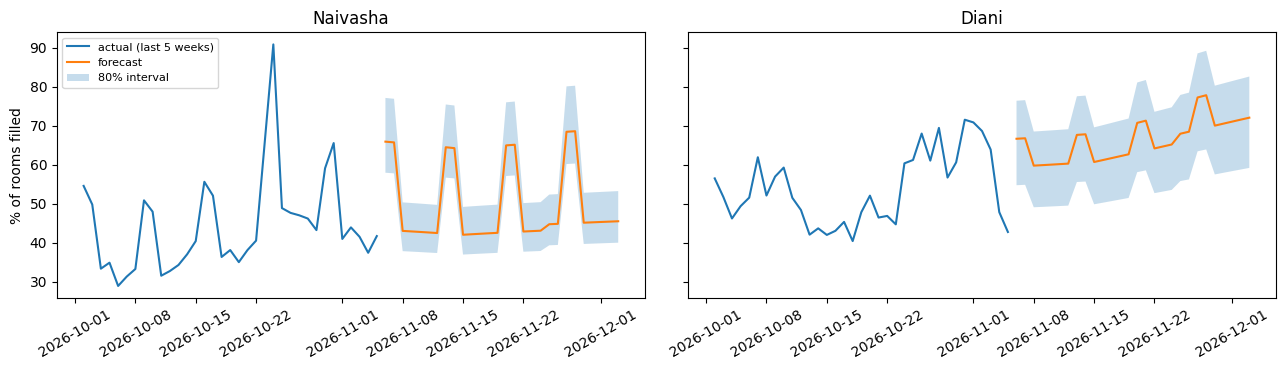

In [6]:
import importlib

import matplotlib.pyplot as plt

import locat.forecasting.features as ffeat
import locat.forecasting.model as fmodel

importlib.reload(ffeat)
importlib.reload(fmodel)

feats = ffeat.build_features(cal, idx_map)
q = pd.read_csv(out_dir / "forecast_interval_quantiles.csv", index_col=0)

# Regression test 1: same features as the notebook
pd.testing.assert_frame_equal(feats.loc[X_all.index], X_all[feats.columns], check_freq=False)
print("regression test 1 passed: features match the notebook")

# Regression test 2: refit at the last backtest origin and reproduce the backtest forecasts
o = origins[-1]
fc_o = fmodel.OccupancyForecaster(feats, q).fit(occ.loc[:o])
worst = 0.0
for dest in DESTINATIONS:
    new = fc_o.forecast(dest, horizon=28)["forecast"]
    old = (res[(res["method"] == "ridge_full") & (res["destination"] == dest) & (res["origin"] == o)]
           .set_index("date")["forecast"])
    worst = max(worst, float(np.max(np.abs(new.values - old.reindex(new.index).values))))
print(f"regression test 2: origin {o.date()}, largest difference {worst:.2e}")
assert worst < 1e-9
print("regression test 2 passed: the module reproduces the backtest forecasts")

# Live forecast: fit on all history, forecast 28 days from the day after the last observation
live = fmodel.OccupancyForecaster(feats, q).fit(occ)
print(f"\nlive forecast: {live.last_date.date() + pd.Timedelta(days=1)} onward, 28 days")

summary = []
for dest in DESTINATIONS:
    f = live.forecast(dest, 28)
    nights = feats.loc[f.index, "fri_sat_night"] == 1
    summary.append({
        "destination": dest,
        "last_28d_actual": occ[dest].tail(28).mean(),
        "next_28d_forecast": f["forecast"].mean(),
        "difference": f["forecast"].mean() - occ[dest].tail(28).mean(),
        "mean_width_pts": 100 * (f["upper"] - f["lower"]).mean(),
        "fri_sat_minus_other_pts": 100 * (f.loc[nights, "forecast"].mean() - f.loc[~nights, "forecast"].mean()),
    })
print(pd.DataFrame(summary).set_index("destination").round(3).to_string())

nv = live.forecast("Naivasha", 28)
nv_view = pd.DataFrame({
    "day": nv.index.strftime("%a %d %b"),
    "forecast_pct": (100 * nv["forecast"]).round(0).astype(int),
    "range_pct": [f"{100 * lo:.0f}-{100 * hi:.0f}" for lo, hi in zip(nv["lower"], nv["upper"])],
    "fri_sat": feats.loc[nv.index, "fri_sat_night"].astype(int).to_numpy(),
    "payday": feats.loc[nv.index, "payday_window"].astype(int).to_numpy(),
})
print("\nNaivasha, day by day:")
print(nv_view.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, dest in zip(axes, ["Naivasha", "Diani"]):
    recent = occ[dest].tail(35)
    f = live.forecast(dest, 28)
    ax.plot(recent.index, 100 * recent, label="actual (last 5 weeks)")
    ax.plot(f.index, 100 * f["forecast"], label="forecast")
    ax.fill_between(f.index, 100 * f["lower"], 100 * f["upper"], alpha=0.25, label="80% interval")
    ax.set_title(dest)
    ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("% of rooms filled")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## **4.12 Review of results: the forecaster in the project and the live forecast (step 4.11)**

### **4.12.1 Verdict**
The move into the project worked: both regression tests pass, with a largest difference
of exactly 0 (0.00e+00), so `features.py` and `model.py` compute the same thing as the
notebook. The live forecast is mostly sensible, but one destination does not look right.
Diani's forecast sits 12.4 points above the last 28 days of actuals, and it starts at 67%
the day after the actuals read 43%. Before the advisor uses any forecast, we test whether
that is a model flaw. Of the five predictions, two held fully, two held with one
destination just outside the stated range, and one missed because of Diani.

### **4.12.2 Prediction scorecard**

| Prediction (4.11.3) | Result | Verdict |
|---|---|---|
| Both regression tests pass | Differences exactly 0 | Held |
| 28-day averages inside the stated ranges | Mara 0.596 (0.50-0.60), Naivasha 0.499 (0.47-0.57), Lamu 0.576 (0.48-0.58) inside; Diani 0.665 (0.55-0.66) and Amboseli 0.521 (0.43-0.52) just outside, by 0.005 and 0.001 | 3 of 5 inside; the two misses are at the edge |
| Forecast average within 0.08 of the last 28 actual days | -0.032, +0.038, +0.030, -0.036; Diani +0.124 | Missed for Diani |
| Naivasha Fri/Sat nights at least 20 points above other nights | 22.5 points | Held |
| Interval width 12 to 21 points in every destination | 14.5 to 20.4; Diani 21.6 | 4 of 5 (Diani 0.6 over) |

My ranges came from hand arithmetic on the generator, so the edge misses (Amboseli by
0.001) tell us little. The Diani miss in prediction 3 is the one that matters.

### **4.12.3 What the numbers show**

#### **4.12.3.1 The module is a faithful copy**
Refitting at the last backtest origin (4 Oct 2026) reproduces the backtest forecasts
with a largest difference of exactly zero, which is expected: same data, same code
path. The app and the notebooks can now share this code.

#### **4.12.3.2 The live forecast, all destinations**

| Destination | Last 28 days actual | Next 28 days forecast | Difference | Width (points) | Fri/Sat minus other (points) |
|---|---|---|---|---|---|
| Maasai Mara | 0.628 | 0.596 | -0.032 | 20.4 | 2.2 |
| Naivasha | 0.461 | 0.499 | +0.038 | 14.5 | 22.5 |
| Diani | 0.541 | 0.665 | +0.124 | 21.6 | 6.0 |
| Lamu | 0.546 | 0.576 | +0.030 | 20.0 | 4.7 |
| Amboseli | 0.557 | 0.521 | -0.036 | 17.9 | 1.1 |

Maasai Mara and Amboseli are forecast a little lower than recently, which fits November
being a quieter month for them. Naivasha rises because schools are out for the whole
period. The weekend gaps follow the domestic share: 22.5 points in Naivasha (90%
domestic) against 1 to 2 points in the safari destinations.

#### **4.12.3.3 Naivasha, day by day**
The forecast shows a clean pattern: Friday and Saturday at 64% to 69%, other nights at
42% to 45%. From 25 November the payday window lifts everything by 2 to 3 points
(43% to 45%, 65% to 68%), which matches the estimated payday effect of about 4.5%. The
chart also shows a 91% actual on 24 October, outside any interval. Our generator has no
special effect at the start of the school break, so that spike is noise, and a few extreme
days are expected over 1,040 days.

#### **4.12.3.4 Diani: why it looks wrong, and what we do not yet know**
The chart shows Diani's actuals falling from about 71% (1 November) to 43% (5 November),
then a forecast starting at 67%, drifting up to 72% by 3 December. Part of the rise is
real: schools are out all month, the payday window opens on 25 November, and December's
season approaches. But a 12.4-point jump is large. Two candidate explanations, neither
tested:

- **The smooth seasonal curve anticipates a step.** In our generator Diani's own season
  jumps from 0.95 in November to 1.20 on 1 December. A smooth curve rises gradually
  instead, so it over-forecasts late November and under-forecasts early December. This fits
  two earlier findings: Diani had the largest remaining gap to the ceiling (0.8 points),
  and its saved error percentiles lean toward actuals below the forecast (-0.197 against
  +0.137).
- **Persistence in the noise.** The last five low values may be noise that lingers for a
  few days (the generator's day-to-day noise is correlated), and the model ignores recent
  values by design. This would affect only the first days of the forecast.

#### **4.12.3.5 Interval widths**
Widths run from 14.5 points (Naivasha) to 21.6 (Diani). Diani's is the widest because
the forecast level is the highest, and the intervals are a percentage of the forecast.

### **4.12.4 Limits**
- This live forecast covers only 28 days, because that is the horizon we validated.
- The forecast ignores recent deviations from the model, so it cannot react to a
  sudden change in the last few days.

### **4.12.5 Decision**
Accept the modules. Hold back the Diani and Lamu forecasts from the advisor until we have
compared them with the generator's noise-free truth. That comparison also tells us
how far past 28 days the forecast can be trusted.

## **4.13 Next step: compare the live forecast with the noise-free truth for 146 days**

### **4.13.1 Why**
The backtest measures error against noisy actuals, so noise (about 4.8 points) hides
the model's own mistakes. For the future, our generator can tell us the noise-free
expected occupancy, the truth, and we can compare the forecast with it directly. That
isolates the model's systematic errors. This only works because the data are synthetic.

### **4.13.2 Method**
1. Add an optional argument `normalise_until` to the generator. It lets the future be
   generated while the normalisation stays fixed at the history, as in the real data.
   (Edit in Part A.)
2. Check that the default behaviour has not changed (the noise-free history must equal
   the oracle from 4.1).
3. Generate the noise-free truth up to 31 Mar 2027, 146 days past the last observation,
   and compare it with the live forecast.
4. Report mean absolute difference by horizon band (days 1-28, 29-60, 61-90, 91-146),
   mean signed difference by month, a close look at Diani around 1 December, and
   Christmas and New Year in Naivasha.

### **4.13.3 Predictions (written before the run)**
1. The default behaviour is unchanged (the check passes).
2. Over days 1-28 the mean absolute difference from the truth is **3.5 points or less in
   every destination**, and Diani's is the largest.
3. For days 61-90 the mean absolute difference stays **within 1.0 point** of the days
   1-28 value in every destination (no degradation with horizon).
4. For Diani, the forecast **exceeds the truth by at least 2 points on average for the
   rest of November**, and **falls short by at least 2 points in the first week of
   December** (the smooth curve misses the step).
5. In Naivasha, the forecast for **25 and 26 December is at least 85%**, and the average
   difference from the truth is **at most 2 points in absolute value in every month** from
   November to March.

### **4.13.4 Decision rule**
- If the difference from the truth is 3.5 points or less everywhere and does not degrade
  by more than 1 point up to day 90, the validated horizon extends to 90 days (the
  intervals are reused and flagged as extrapolated beyond 28 days).
- If any destination has a monthly average difference of 3 points or more, we run a
  seasonal-flexibility experiment (more annual terms, or month indicators) before the
  advisor uses that destination.
- Otherwise the horizon stays at 28 days.

check passed: default behaviour unchanged

forecast horizon compared: 146 days, 2026-11-06 to 2027-03-31

Mean absolute difference between forecast and noise-free truth (points), by horizon:
band         days 1-28  days 29-60  days 61-90  days 91-146
destination                                                
Maasai Mara        2.6         2.4         0.5          1.5
Naivasha           2.7         4.1         3.2          1.4
Diani              4.2         4.1         1.0          2.1
Lamu               3.7         4.2         0.8          1.7
Amboseli           3.4         1.2         0.8          1.8

Mean signed difference by month (forecast minus truth, points):
month        2026-11  2026-12  2027-01  2027-02  2027-03
destination                                             
Maasai Mara      2.6     -2.5      0.2     -0.4     -0.4
Naivasha        -2.5     -4.1     -3.3     -1.8     -1.1
Diani            3.7     -4.9     -0.9     -1.3     -1.1
Lamu             3.2     -4.9     -0.9 

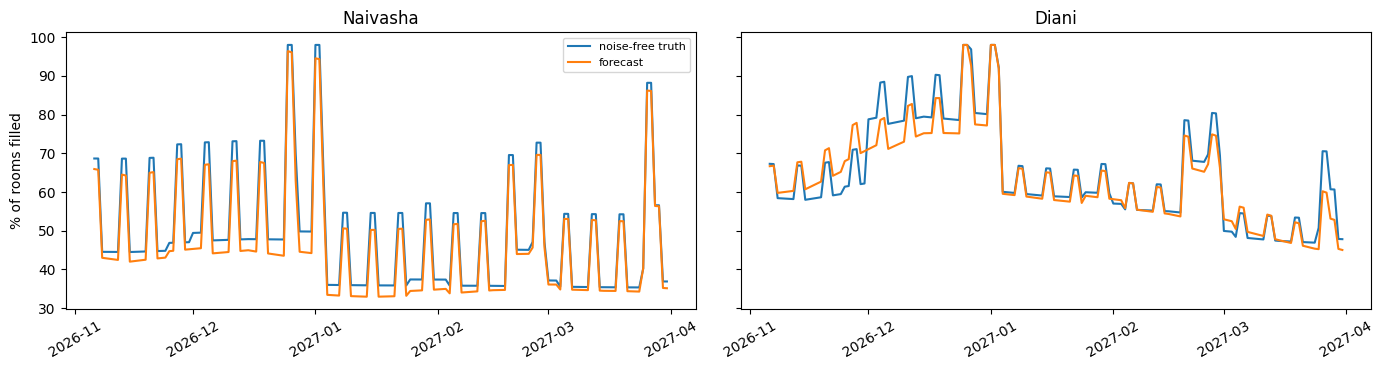

In [7]:
importlib.reload(synth)

# 0) The edit must not change default behaviour
chk = synth.generate_history(
    cal, params, month_adjust, dict(settings, noise_sd=0.0), idx_map, HISTORY_END
)
pd.testing.assert_frame_equal(chk, oracle_hist)
print("check passed: default behaviour unchanged\n")

# 1) Noise-free truth for the future (normalisation fixed at the history)
FUTURE_END = pd.Timestamp("2027-03-31")
truth_future = synth.generate_history(
    cal, params, month_adjust, dict(settings, noise_sd=0.0), idx_map, FUTURE_END,
    normalise_until=HISTORY_END,
)
truth_w = truth_future.pivot(index="date", columns="destination", values="occupancy")[DESTINATIONS]

# 2) The live forecast for the same dates
horizon = (FUTURE_END - live.last_date).days
parts = []
for dest in DESTINATIONS:
    f = live.forecast(dest, horizon)
    parts.append(pd.DataFrame({
        "destination": dest, "date": f.index, "h": np.arange(1, horizon + 1),
        "forecast": f["forecast"].values, "truth": truth_w.loc[f.index, dest].values,
    }))
cmp_ = pd.concat(parts, ignore_index=True)
cmp_["err_pts"] = 100 * (cmp_["forecast"] - cmp_["truth"])
cmp_["abs_err_pts"] = cmp_["err_pts"].abs()
cmp_["band"] = pd.cut(cmp_["h"], [0, 28, 60, 90, horizon],
                      labels=["days 1-28", "days 29-60", "days 61-90", f"days 91-{horizon}"])
cmp_["month"] = cmp_["date"].dt.strftime("%Y-%m")
print(f"forecast horizon compared: {horizon} days, {cmp_['date'].min().date()} to {cmp_['date'].max().date()}\n")

print("Mean absolute difference between forecast and noise-free truth (points), by horizon:")
print(cmp_.pivot_table(index="destination", columns="band", values="abs_err_pts",
                       aggfunc="mean", observed=True).loc[DESTINATIONS].round(1).to_string())

print("\nMean signed difference by month (forecast minus truth, points):")
print(cmp_.pivot_table(index="destination", columns="month", values="err_pts",
                       aggfunc="mean").loc[DESTINATIONS].round(1).to_string())

dd = cmp_[cmp_["destination"] == "Diani"].set_index("date")
sel = dd.loc["2026-11-24":"2026-12-08"]
print("\nDiani around the 1 December step:")
print(pd.DataFrame({
    "day": sel.index.strftime("%a %d %b"),
    "forecast_pct": (100 * sel["forecast"]).round(0).astype(int).values,
    "truth_pct": (100 * sel["truth"]).round(0).astype(int).values,
    "diff_pts": sel["err_pts"].round(1).values,
}).to_string(index=False))

nvx = cmp_[cmp_["destination"] == "Naivasha"].set_index("date")
for lo, hi in [("2026-12-24", "2026-12-28"), ("2026-12-31", "2027-01-04")]:
    s = nvx.loc[lo:hi]
    print(f"\nNaivasha, {lo} to {hi}:")
    print(pd.DataFrame({
        "day": s.index.strftime("%a %d %b"),
        "forecast_pct": (100 * s["forecast"]).round(0).astype(int).values,
        "truth_pct": (100 * s["truth"]).round(0).astype(int).values,
    }).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
for ax, dest in zip(axes, ["Naivasha", "Diani"]):
    d = cmp_[cmp_["destination"] == dest]
    ax.plot(d["date"], 100 * d["truth"], label="noise-free truth")
    ax.plot(d["date"], 100 * d["forecast"], label="forecast")
    ax.set_title(dest)
    ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("% of rooms filled")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## **4.14 Review of results: forecast against the noise-free truth (step 4.13)**

### **4.14.1 Verdict**
The truth check was the most informative test so far. It shows that forecast error
depends on where in the season a date falls, not on how far ahead it is. It confirms
the Diani step hypothesis from 4.12, and it reveals a new problem: Naivasha is biased
low by 2.5 to 4.1 points from November to January. Applying the decision rule from
4.13.4 as written: the 90-day extension is not approved, and the seasonal-flexibility
experiment is triggered. Of the five predictions, two held, two held in part, and one
was worded ambiguously.

### **4.14.2 Prediction scorecard**

| Prediction (4.13.3) | Result | Verdict |
|---|---|---|
| Default behaviour unchanged | Check passed | Held |
| Days 1-28 difference from truth at most 3.5 points everywhere; Diani largest | Mara 2.6, Naivasha 2.7, Amboseli 3.4 inside; Lamu 3.7 and Diani 4.2 outside; Diani is the largest | Held in part (3 of 5 inside) |
| Days 61-90 within 1.0 point of days 1-28 (no degradation) | Four destinations are 2 to 3 points better at days 61-90; Naivasha is 0.5 worse | The literal wording fails in the favourable direction; the intent holds there (see 4.14.3.1) |
| Diani: over-forecast late November by at least 2 points, under-forecast early December by at least 2 | November +3.7; 1 to 8 December between -5.9 and -9.7 | Held, strongly |
| Naivasha: 25 and 26 December at least 85%, monthly difference at most 2 points | 96% and 96% held; monthly differences -2.5, -4.1, -3.3, -1.8, -1.1 | First part held; second part missed |

### **4.14.3 What the numbers show**

#### **4.14.3.1 Error follows the season, not the horizon**

| Destination | Days 1-28 | Days 29-60 | Days 61-90 | Days 91-146 |
|---|---|---|---|---|
| Maasai Mara | 2.6 | 2.4 | 0.5 | 1.5 |
| Naivasha | 2.7 | 4.1 | 3.2 | 1.4 |
| Diani | 4.2 | 4.1 | 1.0 | 2.1 |
| Lamu | 3.7 | 4.2 | 0.8 | 1.7 |
| Amboseli | 3.4 | 1.2 | 0.8 | 1.8 |

Days 29-60 (roughly 4 December to 4 January) are the worst band in three destinations,
and days 61-90 (January to early February) are among the best. Error does not rise with
distance; it rises around the festive season and its seasonal steps. By the rule as
written (3.5 points or less everywhere, no band worse than the first by more than 1
point) the 90-day extension is not approved: Naivasha, Diani and Lamu all have a band
above 3.5, and Naivasha's days 29-60 are 1.4 above its first band. I apply the rule as
written. The pattern also suggests the real constraint is the seasonal fit, so the
horizon is revisited after the experiment in 4.15.

#### **4.14.3.2 Monthly bias (forecast minus truth, points)**

| Destination | Nov | Dec | Jan | Feb | Mar |
|---|---|---|---|---|---|
| Maasai Mara | +2.6 | -2.5 | +0.2 | -0.4 | -0.4 |
| Naivasha | -2.5 | -4.1 | -3.3 | -1.8 | -1.1 |
| Diani | +3.7 | -4.9 | -0.9 | -1.3 | -1.1 |
| Lamu | +3.2 | -4.9 | -0.9 | -0.4 | +0.4 |
| Amboseli | +3.6 | +0.5 | +0.5 | -0.6 | -0.2 |

Seven of the 25 cells are 3 points or more in absolute value, all in November,
December or January. By the second rule in 4.13.4, this triggers the experiment.

#### **4.14.3.3 Diani and the 1 December step: confirmed**
In the last week of November the forecast is 5.7 to 8.4 points above the truth, and
on 1 December the truth jumps by about 17 points while the forecast hardly moves, leaving
it 6 to 10 points low in the first week. The chart shows the shortfall lasting through
December (monthly -4.9), not only the first week. The smooth annual curve anticipates a
step it cannot follow, then lags behind it. Lamu behaves the same way, as expected from
its identical monthly pattern. This confirms the first explanation proposed in 4.12.3.4.

#### **4.14.3.4 Christmas and New Year in Naivasha**
The model sees the sold-out Christmas weekend: 96% forecast for 25 and 26 December
against a truth of 98% (the cap), then 63% against 70% on the 27th. New Year is 95%
and 94% against 98%, then 62% against 67%. This is the clearest demo story: the advisor
can tell a Naivasha host a month ahead that Christmas will be full.

#### **4.14.3.5 Naivasha is low in every month**
The Naivasha difference is negative in all five months (-2.5 to -1.1). On the chart the
forecast sits slightly under the truth at every peak, by about 5% at weekends. Three
candidate causes, each too small alone: ridge shrinkage; taking the exponential of a log
prediction gives a median rather than a mean (about 0.7%, 0.3 to 0.5 points); and the
estimated growth is 4.2% against the true 5%, worth about half a point by this date. Together
they explain perhaps 1 point of the 2.5 to 4.1, so the cause is not found. The experiment
in 4.15 shows whether it is tied to the seasonal fit.

### **4.14.4 Limits**
- The "truth" is the noise-free expectation; the model was fitted on one noisy dataset
  (seed 42), so part of any gap is that dataset's noise, plausibly 1 to 2 points.
- In real life no such truth exists. This check is available only because the data are
  synthetic.

### **4.14.5 Decision**
- The horizon stays at 28 days for now.
- Run a seasonal-flexibility experiment (4.15), choosing by the backtest, not by this
  truth. Choosing a model because it matches the future truth would be peeking.
- Timebox: Chapter 4 closes after 4.15, and Chapter 5 (the price advisor) starts.

## **4.15 Next step: a seasonal-flexibility experiment, chosen by the backtest**

### **4.15.1 Why**
The step bias in Diani and Lamu points at the annual curve (three sine and cosine pairs),
and Naivasha's low bias might be linked to it or to shrinkage. We try a more flexible
curve and weaker shrinkage, and judge them by the rolling backtest. The truth is used
afterwards only to see whether the chosen variant removes the bias.

### **4.15.2 Variants**

| Name | Annual curve | Ridge strength |
|---|---|---|
| A (current) | 3 sine/cosine pairs | 1.0 |
| B | 6 pairs | 1.0 |
| C | 3 pairs | 0.1 |
| D | 6 pairs | 0.1 |
| E (diagnostic only) | one indicator per month | 1.0 |

**E is never adopted from this experiment.** Our generator changes season in steps at
month boundaries, which is an artifact of how we wrote its assumptions, and month
indicators would match that artifact exactly. Real seasons are smoother. E is reported
only as an upper bound on what knowing the steps would be worth.

### **4.15.3 Selection rule (fixed before the run)**
Adopt the best of B, C and D if it (a) lowers the overall backtest error by at least
0.15 points against A and (b) is no more than 0.2 points worse than A in any
destination. If more than one qualifies, take the lowest error; if two are within 0.05
of each other, take the simpler (fewer terms, stronger shrinkage).

### **4.15.4 Predictions (written before the run)**
1. B lowers the overall backtest error by 0.1 to 0.4 points, with gains of at least 0.3
   points in both Diani and Lamu.
2. Lowering the ridge strength (C against A) changes the overall error by less than 0.1.
3. E reaches the best error, within 0.2 of the oracle's 4.8, and beats B by at least 0.1.
4. In the truth check, B cuts Diani's November over-forecast and December shortfall by
   at least a third; E brings both to 1.5 points or less in absolute value.
5. Naivasha's negative bias is not removed: under B, at least two of November, December
   and January stay at -2 points or lower.

### **4.15.5 Decision rule**
- If a variant meets the selection rule, adopt it and rerun the truth check on it.
- If none does, keep A and accept the step error as a documented limitation: it is
  smaller than the 80% interval and rarely changes the advice (hold, raise, lower).

In [8]:
# ---- feature sets ----
fourier_cols = [c for c in X_all.columns if c.startswith(("sin", "cos"))]
base_cols = [c for c in X_all.columns if c not in fourier_cols]  # flags, log_intl, trend


def with_fourier(K):
    X = X_all[base_cols].copy()
    doy = X.index.dayofyear.to_numpy()
    for k in range(1, K + 1):
        X[f"sin{k}"] = np.sin(2 * np.pi * k * doy / 365.25)
        X[f"cos{k}"] = np.cos(2 * np.pi * k * doy / 365.25)
    return X


X_k6 = with_fourier(6)
month_dummies = pd.get_dummies(
    pd.Series(X_all.index.month, index=X_all.index), prefix="m", drop_first=True
).astype(float)
X_month = pd.concat([X_all[base_cols], month_dummies], axis=1)


def make_forecaster(X, alpha):
    cols = list(X.columns)

    def fc(train, origin, horizon, dest):
        dates = _dates(origin, horizon)
        model = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
        model.fit(X.loc[train.index, cols], np.log(train.values))
        pred = np.exp(model.predict(X.loc[dates, cols]))
        return pd.Series(np.clip(pred, 0.01, 0.98), index=dates)

    return fc


variants_new = {
    "B_K6_alpha1": (X_k6, 1.0),
    "C_K3_alpha0.1": (X_all, 0.1),
    "D_K6_alpha0.1": (X_k6, 0.1),
    "E_month_dummies (diagnostic)": (X_month, 1.0),
}

# ---- rolling backtest (A is reused from step 4.3) ----
new2 = pd.concat(
    [evaluate(make_forecaster(X, a), name) for name, (X, a) in variants_new.items()],
    ignore_index=True,
)
new2["error_pts"] = 100 * (new2["forecast"] - new2["actual"])
new2["abs_error_pts"] = new2["error_pts"].abs()
A_rows = res[res["method"] == "ridge_full"].assign(method="A_current_K3_alpha1")
allv = pd.concat([A_rows, new2], ignore_index=True)

mae3 = allv.pivot_table(index="method", columns="destination", values="abs_error_pts",
                        aggfunc="mean")[DESTINATIONS]
mae3["ALL"] = allv.groupby("method")["abs_error_pts"].mean()
mae3.loc["oracle (ceiling)"] = mae2.loc["oracle_knows_the_rules"]
order3 = ["A_current_K3_alpha1"] + list(variants_new) + ["oracle (ceiling)"]
print("Backtest MAE (points):")
print(mae3.loc[order3].round(2).to_string())

A = mae3.loc["A_current_K3_alpha1"]
print("\nSelection rule (gain >= 0.15 overall, no destination worse than +0.2):")
for name in ["B_K6_alpha1", "C_K3_alpha0.1", "D_K6_alpha0.1"]:
    gain = A["ALL"] - mae3.loc[name, "ALL"]
    worst = (mae3.loc[name, DESTINATIONS] - A[DESTINATIONS]).max()
    print(f"  {name}: gain {gain:+.2f} | worst destination change {worst:+.2f} | "
          f"meets rule: {gain >= 0.15 and worst <= 0.2}")


# ---- truth diagnostic (for understanding only, not for selection) ----
def truth_check(X, alpha):
    cols = list(X.columns)
    dates = truth_w.index[truth_w.index > occ.index.max()]
    parts = []
    for dest in DESTINATIONS:
        model = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
        model.fit(X.loc[occ.index, cols], np.log(occ[dest].values))
        f = np.clip(np.exp(model.predict(X.loc[dates, cols])), 0.01, 0.98)
        parts.append(pd.DataFrame({
            "destination": dest, "date": dates, "h": np.arange(1, len(dates) + 1),
            "err": 100 * (f - truth_w.loc[dates, dest].values),
        }))
    return pd.concat(parts, ignore_index=True)


diag = []
for name, (X, a) in {"A_current_K3_alpha1": (X_all, 1.0), **variants_new}.items():
    t = truth_check(X, a)
    t["abs"] = t["err"].abs()
    t["month"] = t["date"].dt.strftime("%Y-%m")
    mb = t.pivot_table(index="destination", columns="month", values="err", aggfunc="mean")
    band = t.groupby(pd.cut(t["h"], [0, 28, 60, 90, 146]), observed=True)["abs"].mean()
    diag.append({
        "variant": name,
        "MAE d1-28": band.iloc[0], "MAE d29-60": band.iloc[1],
        "MAE d61-90": band.iloc[2], "MAE d91-146": band.iloc[3],
        "Diani Nov": mb.loc["Diani", "2026-11"], "Diani Dec": mb.loc["Diani", "2026-12"],
        "Lamu Nov": mb.loc["Lamu", "2026-11"], "Lamu Dec": mb.loc["Lamu", "2026-12"],
        "Naiv Nov": mb.loc["Naivasha", "2026-11"], "Naiv Dec": mb.loc["Naivasha", "2026-12"],
        "Naiv Jan": mb.loc["Naivasha", "2027-01"],
    })
print("\nTruth diagnostic (points; MAE pooled over destinations; monthly mean differences):")
print(pd.DataFrame(diag).set_index("variant").round(1).to_string())

Backtest MAE (points):
destination                   Maasai Mara  Naivasha  Diani  Lamu  Amboseli   ALL
method                                                                          
A_current_K3_alpha1                  5.92      3.96   5.76  5.12      5.45  5.24
B_K6_alpha1                          5.94      4.06   5.53  4.88      5.44  5.17
C_K3_alpha0.1                        5.92      3.97   5.77  5.12      5.45  5.25
D_K6_alpha0.1                        5.95      4.06   5.55  4.86      5.45  5.17
E_month_dummies (diagnostic)         5.77      4.06   5.30  4.72      5.32  5.03
oracle (ceiling)                     5.63      3.89   5.05  4.40      4.93  4.78

Selection rule (gain >= 0.15 overall, no destination worse than +0.2):
  B_K6_alpha1: gain +0.07 | worst destination change +0.10 | meets rule: False
  C_K3_alpha0.1: gain -0.00 | worst destination change +0.01 | meets rule: False
  D_K6_alpha0.1: gain +0.07 | worst destination change +0.10 | meets rule: False

Truth diagnosti

## **4.16 Review of results: the seasonal-flexibility experiment (step 4.15)**

### **4.16.1 Verdict**
No variant meets the selection rule fixed in 4.15.3, so the current model (variant A:
three sine/cosine pairs, ridge strength 1.0) stays. The best candidates gain only 0.07
points of backtest error against the 0.15 required. The experiment still taught
three things. A more flexible annual curve helps Diani and Lamu a little in the backtest.
Weaker shrinkage changes nothing. Neither flexibility nor knowing the exact month steps
removes Naivasha's low bias, so that bias comes from somewhere else. Of the five
predictions, two held, one held in part, one half held and one missed on size.

### **4.16.2 Prediction scorecard**

| Prediction (4.15.4) | Result | Verdict |
|---|---|---|
| B lowers overall error by 0.1 to 0.4, gaining at least 0.3 in both Diani and Lamu | Overall +0.07; Diani +0.23 (5.76 to 5.53); Lamu +0.24 (5.12 to 4.88) | Missed on size; direction right |
| Lower ridge strength changes overall error by less than 0.1 | C: 5.25 against 5.24 | Held |
| E is best, within 0.2 of the oracle, and beats B by at least 0.1 | E 5.03 is best and beats B by 0.14; the gap to the oracle is 0.25 | Held in part (0.05 outside the band) |
| B cuts Diani's November and December bias by a third; E brings both to 1.5 points or less | B: November +3.7 to +1.4 (cut by 62%), December -4.9 to -4.0 (18%); E: November -0.3, December -3.5 | Half held (November yes, December no) |
| Under B, at least two of Naivasha's November to January biases stay at -2 or lower | -3.0, -3.3, -3.3 | Held |

### **4.16.3 What the numbers show**

#### **4.16.3.1 Backtest and selection rule**

| Variant | Overall MAE | Gain against A | Worst destination change | Meets the rule |
|---|---|---|---|---|
| A (3 pairs, 1.0) | 5.24 | n/a | n/a | n/a |
| B (6 pairs, 1.0) | 5.17 | +0.07 | +0.10 | No |
| C (3 pairs, 0.1) | 5.25 | -0.00 | +0.01 | No |
| D (6 pairs, 0.1) | 5.17 | +0.07 | +0.10 | No |
| E (month indicators, diagnostic) | 5.03 | +0.21 | n/a | Not eligible |
| Oracle (ceiling) | 4.78 | n/a | n/a | n/a |

B and D are practically identical, as are A and C, so ridge strength is irrelevant at
this data size. A more flexible curve gives about 0.07 overall, concentrated in Diani
and Lamu (about 0.24 each).

#### **4.16.3.2 The practical floor is about 5.0, not 4.8**
Even E, which knows the month steps exactly, sits 0.25 above the oracle. That gap is
the price of estimating everything from under three years of noisy data, so a realistic
best is near 5.0. Our model is about 0.2 above that (4%). There is very little left to
gain.

#### **4.16.3.3 A tension I will not paper over**
In the forward truth window (6 November to 3 December), B cuts the 28-day error from 3.3
to 2.4 points and fixes most of Diani's and Lamu's November over-forecast. The backtest
sees only 0.07 because the biggest step of the year, 1 December, appears in just a few of
its windows. B costs nothing and is not worse anywhere by more than 0.1 in the backtest,
so it is tempting. But the rule was fixed before the run, and choosing B because the
truth diagnostic likes it would be selecting on the future. I keep A. If you want B, say
so as a new, explicit decision, with its true reason (a harmless change that helps the
season where the demo sits) written down.

#### **4.16.3.4 December is still short, even with month indicators**
Under E, Diani's December difference is -3.5 and Lamu's -2.9. So the December shortfall
is not only a curve problem. With month indicators each month's level rests on just two
Decembers (2024 and 2025) of correlated daily noise, and a rough estimate puts the
sampling error of such a level at 2 to 3 points. Part of the December gap may therefore
be this dataset's noise. That is a rough estimate and has not been tested.

#### **4.16.3.5 Naivasha's low bias is unmoved**
Naivasha in November, December and January: A -2.5, -4.1, -3.3; B -3.0, -3.3, -3.3; E
-2.5, -3.7, -3.4. No variant changes it, so the annual curve is not the cause. The
earlier candidates (ridge shrinkage, median against mean, slightly low growth) are not
confirmed either; shrinkage is ruled out by C. The cause stays open. For scale: Naivasha's
80% interval is about 6 to 7 points on each side, so a bias of 2.5 to 4 points sits
inside it.

### **4.16.4 Limits**
- All findings are for one synthetic dataset (seed 42), and the truth diagnostic is
  available only because the data are synthetic.
- The monthly steps in our generator are an artifact of the assumption tables, so the
  value of E is an upper bound, not a promise.

### **4.16.5 Decision**
Keep A as the final model. Close Chapter 4 with a model card that states, with numbers,
what was validated and what was not. The two known biases (the December step in Diani and
Lamu, the low level in Naivasha) go into the card as documented limitations.

## **4.17 Next step: close Chapter 4 with a model card**

### **4.17.1 Why**
A forecaster used by hosts, and judged on responsible development, needs one page that
says what it is for, how it was tested and where it falls short. As with the data card,
every number is computed from this notebook's variables, so the card cannot drift from the
evidence.

### **4.17.2 Contents**
1. **Intended use and model**: the weekly 28-day outlook, features, interval method.
2. **Evidence**: backtest against baselines and the ceiling, interval coverage, which
   effects the advisor may quote and how.
3. **Known limitations, with numbers**: the December step, Naivasha's low level, the
   school-break effect, Easter, the 28-day horizon, new hosts, no real-data validation.
4. **How to refresh** with real bookings.

### **4.17.3 Check**
This step is documentation, so there are no predictions. The check is that every
statement in the card can be traced to a numbered review cell (4.2, 4.4, 4.8, 4.10,
4.12, 4.14, 4.16) and that no number is typed by hand.

### **4.17.4 Output**
`data/processed/MODEL_CARD.md`, printed in full for you to read.

In [9]:
# ---- numbers, all taken from earlier cells ----
full_mae = mae2.loc["ridge_full", "ALL"]
best_base = mae2.loc[baselines, "ALL"].idxmin()
best_base_mae = mae2.loc[best_base, "ALL"]
ceiling = mae2.loc["oracle_knows_the_rules", "ALL"]
gap_closed = (best_base_mae - full_mae) / (best_base_mae - ceiling)

coverage = ivl["covered"].mean()
width = ivl["width_pts"].mean()
cov_by_dest = (100 * ivl.groupby("destination")["covered"].mean()).loc[DESTINATIONS].round(1)

month_bias = (
    cmp_.pivot_table(index="destination", columns="month", values="err_pts", aggfunc="mean")
    .loc[DESTINATIONS, ["2026-11", "2026-12", "2027-01"]].round(1)
)
mae_by_dest = mae2.loc[["ridge_full", best_base, "oracle_knows_the_rules"], DESTINATIONS + ["ALL"]].round(1)

card = f"""# Loca-T occupancy forecaster: model card

STATUS: validated on SYNTHETIC data only. It has NOT been validated on real bookings.

## 1. Intended use
A weekly outlook of room occupancy, {fmodel.CAP:.0%} cap, 28 days ahead, for small hosts in
{len(DESTINATIONS)} destinations ({', '.join(DESTINATIONS)}), with an 80% interval, as the input to
price suggestions. Not for forecasting beyond 28 days.

## 2. Model
- One ridge regression per destination on log occupancy (strength {fmodel.ALPHA}), refitted weekly
  on all history to date.
- Features known in advance: Friday/Saturday night, school break, long weekend, Easter
  period, payday window, log of the smoothed KNBS international seasonal index, three annual
  sine/cosine pairs and a linear trend.
- 80% interval: forecast x exp(q10) to forecast x exp(q90), using percentiles of past log
  errors per destination (forecast_interval_quantiles.csv), capped at {fmodel.CAP:.0%}.

## 3. Evidence (rolling backtest: {len(origins)} weekly origins, 28 days ahead)
Mean absolute error, in occupancy points (1 point = 1% of rooms):

{mae_by_dest.to_string()}

- The model closes {gap_closed:.0%} of the gap between the best baseline ({best_base}, {best_base_mae:.1f})
  and the ceiling of a model that knows the generating rules ({ceiling:.1f}).
- 80% intervals cover {coverage:.1%} of actuals (target 80%), mean width {width:.1f} points.
  Coverage by destination (%):
{cov_by_dest.to_string()}
- Effects the advisor may quote (number = bias and spread both within 0.03; range = both
  within 0.06; otherwise qualitative):
{labels.to_string()}

## 4. Known limitations
1. **Seasonal steps.** Against the generator's noise-free truth, the forecast minus truth by
   month (points) for the next season is:
{month_bias.to_string()}
   Diani and Lamu run high in late November and low through December, because the smooth
   annual curve does not follow a step in their own season. Naivasha runs low by 2.5 to
   4 points from November to January; the cause is not found.
2. **School-break effect** is estimated 0.01 to 0.04 too low; **Easter** cannot be quoted as
   a number (about 15 training days).
3. **Horizon.** Validated only for 28 days. Error follows the season more than the horizon, but
   the 90-day extension rule was not met.
4. **New hosts** with little history are not covered; the intervals assume a full history.
5. **No real bookings** have been tested. The synthetic world follows rules we wrote, and the
   model is close to that form, so real performance will be lower.

## 5. How to refresh
Replace synthetic_occupancy.csv with real daily occupancy, rerun notebooks 03 and 04, and
recompute the baselines, the interval percentiles and the quoting labels before trusting any
number above.
"""
(out_dir / "MODEL_CARD.md").write_text(card)
print(card)

# Loca-T occupancy forecaster: model card

STATUS: validated on SYNTHETIC data only. It has NOT been validated on real bookings.

## 1. Intended use
A weekly outlook of room occupancy, 98% cap, 28 days ahead, for small hosts in
5 destinations (Maasai Mara, Naivasha, Diani, Lamu, Amboseli), with an 80% interval, as the input to
price suggestions. Not for forecasting beyond 28 days.

## 2. Model
- One ridge regression per destination on log occupancy (strength 1.0), refitted weekly
  on all history to date.
- Features known in advance: Friday/Saturday night, school break, long weekend, Easter
  period, payday window, log of the smoothed KNBS international seasonal index, three annual
  sine/cosine pairs and a linear trend.
- 80% interval: forecast x exp(q10) to forecast x exp(q90), using percentiles of past log
  errors per destination (forecast_interval_quantiles.csv), capped at 98%.

## 3. Evidence (rolling backtest: 88 weekly origins, 28 days ahead)
Mean absolute error, in occupancy p

## **4.18 Review of results: the model card (step 4.17)**

### **4.18.1 Verdict**
Every number in the card matches the review cell it came from. The problems are in the
words around the numbers: three statements claim more than the evidence supports, four
relevant facts are missing, one instruction is wrong for real data, and one sentence is
awkward. That makes nine corrections, listed below. Applying them is the last step of
Chapter 4.

### **4.18.2 Checks, statement by statement**

| Card section | Statement | Source | Result |
|---|---|---|---|
| 1 Intended use | "room occupancy, 98% cap, 28 days ahead" | n/a | Awkward: reads as if the outlook has a cap. Fix 1 |
| 2 Model | Features, ridge strength, interval method | 4.3, 4.9 | Correct |
| 2 Model | (missing) the international index adds no accuracy where a host has history | 4.4.3.3 | Missing. Fix 2 |
| 3 Evidence | Error table (5.2, 7.4, 4.8 overall) | 4.3 | Matches |
| 3 Evidence | "closes 82% of the gap" | 4.4.3.1 | Right, but computed from unrounded errors; recomputing from the one-decimal table gives 85%. Fix 3 |
| 3 Evidence | Coverage 80.7%, width 17.5, by destination | 4.10 | Matches |
| 3 Evidence | Quoting labels | 4.8.3.6 | Matches |
| 4.1 Seasonal steps | Monthly difference table | 4.14.3.2 | Matches |
| 4.1 Seasonal steps | "...low through December, **because** the smooth annual curve does not follow a step" | 4.14.3.3, 4.16.3.4 | Overstated. Confirmed for 24 November to 8 December; about 3 points of December shortfall remain even with month indicators and may be dataset noise. Fix 4 |
| 4.1 Seasonal steps | (missing) Amboseli runs 3.6 points high in November | 4.14.3.2 | Missing, and it is one of the seven cells at 3 points or more. Fix 5 |
| 4.1 Seasonal steps | "Naivasha runs low by 2.5 to 4 points; cause not found" | 4.14.3.5, 4.16.3.5 | Correct; add "in every variant tried" and use 4.1 rather than 4. Fix 6 |
| 4.2 | School effect 0.01 to 0.04 low; Easter about 15 days | 4.8.3.3, 4.8.3.5 | Matches |
| 4.3 | Horizon validated for 28 days only | 4.14.3.1 | Matches |
| 4.5 | "real performance **will be** lower" | none | A certainty I cannot support; say "is likely to be lower". Fix 7 |
| (missing) | The backtest uses the international index built from 2024 and 2025 arrivals, a mild look-ahead | 4.3.4, 4.4.3.3 | Missing. Fix 8 (the effect is small: removing it changed the error by 0.1 or less) |
| (missing) | The quoting labels were measured against the generator's exact effects, which real data cannot provide | 4.8.4 | Missing. Added with Fix 8 |
| 5 Refresh | "rerun notebooks 03 and 04" | n/a | Wrong with real data: notebook 03 generates the synthetic data. Fix 9 |

### **4.18.3 Why this matters**
A model card that overstates a cause or promises a result teaches readers to trust it
more than the evidence allows. The December gap is the clearest case: the card said
"because", the experiment said "partly, and some of it may be noise".

### **4.18.4 Decision**
Regenerate the card with the nine corrections. Numbers that appear in the new text
(the late-November and early-December extremes, the month-indicator results, the
Amboseli figure) are computed from variables, not typed. Then Chapter 4 is closed.

## **4.19 Next step: the corrected model card, and the end of Chapter 4**

### **4.19.1 Why**
The first card is accurate on numbers and loose on wording. The corrected card is the
version we will publish with the project.

### **4.19.2 Method**
Add a new code cell below. It recomputes every figure from the notebook's variables,
applies the nine corrections in 4.18.2 and overwrites `data/processed/MODEL_CARD.md`.
The earlier card cell can be deleted.

### **4.19.3 Check**
Documentation again, so no predictions. The check is that each of the nine corrections
shows up in the printed card, and that every number can be traced to a review cell.

### **4.19.4 What comes next**
Chapter 5 turns the forecast into price advice: decision rules, an explicit
assumption about how guests respond to price (our data contain no prices, so this must be
stated as an assumption), and the wording of the host's SMS using the quoting labels.

In [10]:
# ---- numbers, all taken from earlier cells ----
full_mae = mae2.loc["ridge_full", "ALL"]
no_intl_mae = mae2.loc["ridge_no_intl_index", "ALL"]
best_base = mae2.loc[baselines, "ALL"].idxmin()
best_base_mae = mae2.loc[best_base, "ALL"]
ceiling = mae2.loc["oracle_knows_the_rules", "ALL"]
gap_closed = (best_base_mae - full_mae) / (best_base_mae - ceiling)

coverage = ivl["covered"].mean()
width = ivl["width_pts"].mean()
cov_by_dest = (100 * ivl.groupby("destination")["covered"].mean()).loc[DESTINATIONS].round(1)
mae_by_dest = mae2.loc[["ridge_full", best_base, "oracle_knows_the_rules"], DESTINATIONS + ["ALL"]].round(1)

month_bias = (
    cmp_.pivot_table(index="destination", columns="month", values="err_pts", aggfunc="mean")
    .loc[DESTINATIONS, ["2026-11", "2026-12", "2027-01"]].round(1)
)
dd = cmp_[cmp_["destination"] == "Diani"].set_index("date")["err_pts"]
nov_peak = dd.loc["2026-11-24":"2026-11-30"].max()
dec_low = dd.loc["2026-12-01":"2026-12-08"].min()
diag_df = pd.DataFrame(diag).set_index("variant")
e_row = diag_df.loc["E_month_dummies (diagnostic)"]
amb_nov = month_bias.loc["Amboseli", "2026-11"]
nv = month_bias.loc["Naivasha"]
nv_lo, nv_hi = abs(nv.max()), abs(nv.min())
sb_lo, sb_hi = abs(bias["school_out"]).min(), abs(bias["school_out"]).max()
easter_days = int(cal.loc[cal["date"] <= HISTORY_END, "easter_period"].sum())

card = f"""# Loca-T occupancy forecaster: model card (corrected)

STATUS: validated on SYNTHETIC data only (history to {HISTORY_END.date()}). It has NOT been
validated on real bookings.

## 1. Intended use
A weekly outlook of room occupancy (never shown above {fmodel.CAP:.0%}), 28 days ahead, for small
hosts in {len(DESTINATIONS)} destinations ({', '.join(DESTINATIONS)}), with an 80% interval, as the input
to price suggestions. Not for forecasting beyond 28 days.

## 2. Model
- One ridge regression per destination on log occupancy (strength {fmodel.ALPHA}), refitted weekly
  on all history to date.
- Features known in advance: Friday/Saturday night, school break, long weekend, Easter
  period, payday window, log of the smoothed KNBS international seasonal index, three annual
  sine/cosine pairs and a linear trend.
- The international index adds no accuracy where a host has history (backtest error
  {no_intl_mae:.1f} without it, {full_mae:.1f} with it). It is kept as the seasonal prior for new hosts.
- 80% interval: forecast x exp(q10) to forecast x exp(q90), using percentiles of past log
  errors per destination (forecast_interval_quantiles.csv), capped at {fmodel.CAP:.0%}.

## 3. Evidence (rolling backtest: {len(origins)} weekly origins, 28 days ahead)
Mean absolute error, in occupancy points (1 point = 1% of rooms):

{mae_by_dest.to_string()}

- The model closes about {gap_closed:.0%} of the gap between the best baseline ({best_base}, {best_base_mae:.1f})
  and the ceiling of a model that knows the generating rules ({ceiling:.1f}). The percentage is computed
  from unrounded errors, so it can differ slightly from the rounded table.
- 80% intervals cover {coverage:.1%} of actuals (target 80%), mean width {width:.1f} points.
  Coverage by destination (%):
{cov_by_dest.to_string()}
- Effects the advisor may quote (number = bias and spread both within 0.03; range = both
  within 0.06; otherwise qualitative):
{labels.to_string()}
  These labels were measured against the synthetic generator's exact effects. Real bookings
  provide no such yardstick, so the labels must be earned again before any number is quoted.

## 4. Known limitations
1. **Seasonal steps.** Against the generator's noise-free truth, the forecast minus truth by
   month (points) is:
{month_bias.to_string()}
   Diani is up to {nov_peak:+.1f} points high in the last week of November and as low as {dec_low:+.1f} in the first
   week of December. This is mainly a smooth annual curve that does not follow a step in their own
   season (confirmed for 24 November to 8 December). A December shortfall of about 3 points remains even
   with month indicators (Diani {e_row['Diani Dec']:.1f}, Lamu {e_row['Lamu Dec']:.1f}) and may be noise in this dataset (untested).
   Lamu behaves like Diani. Amboseli runs {amb_nov:.1f} points high in November. Naivasha runs low by
   {nv_lo:.1f} to {nv_hi:.1f} points from November to January in every variant tried; the cause is not found.
2. **School-break effect** is estimated {sb_lo:.2f} to {sb_hi:.2f} too low; **Easter** cannot be quoted as a
   number (about {easter_days} training days).
3. **Horizon.** Validated only for 28 days. Error follows the season more than the horizon, but
   the 90-day extension rule was not met.
4. **New hosts** with little history are not covered; the intervals assume a full history.
5. **Mild look-ahead in the backtest.** The international index was built from 2024 and 2025
   arrivals, so early backtest origins see slightly ahead; removing it changed the error by
   {abs(no_intl_mae - full_mae):.1f} points, so the effect is small.
6. **No real bookings** have been tested. The synthetic world follows rules we wrote, and the
   model is close to that form, so real performance is likely to be lower.

## 5. How to refresh with real bookings
Replace synthetic_occupancy.csv with real daily occupancy (same columns). Skip notebook 03, which
generates the synthetic data, rerun notebook 04, and recompute the baselines, the interval
percentiles and the quoting labels before trusting any number above.
"""
(out_dir / "MODEL_CARD.md").write_text(card)
print(card)

# Loca-T occupancy forecaster: model card (corrected)

STATUS: validated on SYNTHETIC data only (history to 2026-11-05). It has NOT been
validated on real bookings.

## 1. Intended use
A weekly outlook of room occupancy (never shown above 98%), 28 days ahead, for small
hosts in 5 destinations (Maasai Mara, Naivasha, Diani, Lamu, Amboseli), with an 80% interval, as the input
to price suggestions. Not for forecasting beyond 28 days.

## 2. Model
- One ridge regression per destination on log occupancy (strength 1.0), refitted weekly
  on all history to date.
- Features known in advance: Friday/Saturday night, school break, long weekend, Easter
  period, payday window, log of the smoothed KNBS international seasonal index, three annual
  sine/cosine pairs and a linear trend.
- The international index adds no accuracy where a host has history (backtest error
  5.3 without it, 5.2 with it). It is kept as the seasonal prior for new hosts.
- 80% interval: forecast x exp(q10) to forecast x exp(